# 📏 Lab 05b (Part 2 of 2): Is It Really Better? Statistical Rigor and Judge Calibration for LLM Evals

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/05b-statistical-rigor-judge-calibration-part-2-lab.ipynb)

⏱️ ~40 min core (Tasks 7–10) · +45 min for the five challenges

**Previously, in Part 1:**<br>
① The PM's +6 is 3 questions, inside ±11 points of noise.<br>
② The 50 questions behave like 12; re-runs swing v2 16 points.<br>
③ Now: the judge says production is **90%**. Can you trust it?

**How this lab works**
- ▶️ **Run**: <kbd>Shift</kbd>+<kbd>Enter</kbd>; 🧰 cells just need running.
- ✋ **Your turn**: fill the `...`; auto-graded.
- ❓ **Quick check**: pick, then run.
- 🔑 **Key takeaway**: the line to remember.

## 🧪 Environment and Setup

▶️ **Run** the next five cells: imports · 🎨 lab kit · 🧰 harness · 🧰 chart helpers · 🧰 catch-up (rebuilds Part 1).

In [ ]:
# Everything below is preinstalled in Google Colab.
# Running locally? pip install numpy pandas scipy matplotlib
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)
print("✅ Environment ready")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

In [ ]:
# @title 🧰 Lab harness: the Brightbook simulator + reference solutions (run me; code is hidden)
# ============================================================
# 🧰 LAB HARNESS — the "infrastructure" for this lab
# ============================================================
# This cell builds everything you'll USE but don't need to write:
#   1. golden       — the 50-case golden set the PM used (expert-graded v1 and v2 answers)
#   2. rerun_golden — re-ask the same 50 questions k more times (answers are random!)
#   3. draw_golden_sets — build many *new* 50-case golden sets from the same traffic
#   4. calib / prod — expert-vs-judge labels, and 2,000 judge-graded production answers
#   5. dashboard    — the PM's 10-metric scorecard
#   6. Helpers: bootstrap_corrected, simulate_null_dashboards, use_or_fallback, pct
#   7. Reference solutions (names start with _reference_) used as safety nets.
#      Peeking is allowed if you're stuck, but try the exercise first!
# Everything is simulated from fixed seeds, so the whole class sees the same numbers.
# Because it is a simulation, we also know the TRUTH (hidden in _TRUTH until Task 10).
# ============================================================
import math
import numpy as np
import pandas as pd
from scipy import stats

def _sig(x):
    return 1.0 / (1.0 + np.exp(-x))

# ---- 0. The latent world: each question has a difficulty; questions in one conversation share it ----
_SU, _SE, _SG = 1.3, 0.8, 0.5           # conversation effect, question effect, v2-vs-v1 per-question effect (logit SDs)
_A, _B, _B_NULL = 1.8517534857123885, 0.21638325191438196, 0.045578400982189834   # calibrated: v1 79%, v2 81% (null: v2 = v1)

def _latent(rng, n_conv, q=5):
    d = np.repeat(rng.normal(0, _SU, n_conv), q) + rng.normal(0, _SE, n_conv * q)
    g = rng.normal(0, _SG, n_conv * q)
    return d, g

# ---- 1. The golden set: 10 (anonymized) customer conversations x 5 follow-up questions -----------------
_CONVS = [
    ("C01", "Consulting S-corp, owner lives in NJ, works in NY", ["Do I file in both states?", "Is my NY income taxed twice?", "Which state gets my S-corp K-1 income?", "Do I need a NY nonresident return?", "Can I claim a credit for NY tax on my NJ return?"]),
    ("C02", "Freelance UX designer paid on 1099-NEC", ["Do I owe self-employment tax?", "Can I deduct my laptop?", "What is the 1099-NEC threshold?", "Can I deduct health insurance premiums?", "Should I pay quarterly estimates?"]),
    ("C03", "Rideshare + delivery driver, one car", ["Standard mileage or actual expenses?", "Can I switch methods this year?", "Are commuting miles deductible?", "Do tolls count on top of mileage?", "What records do I need for mileage?"]),
    ("C04", "Etsy candle shop selling in 30 states", ["Do I collect sales tax myself?", "What is a marketplace facilitator?", "Do I need a resale certificate for wax?", "Is shipping taxable?", "Do I file sales tax returns at all?"]),
    ("C05", "Food-truck LLC, single member", ["When are quarterly estimates due?", "How much should I pay each quarter?", "What is the safe-harbor rule?", "Is there a penalty for underpaying?", "Does my LLC file its own return?"]),
    ("C06", "Landscaping company hiring its first W-2 employee", ["What forms does a new hire fill out?", "How often do I deposit payroll taxes?", "What is FUTA?", "Do I need workers' comp?", "Contractor or employee for seasonal help?"]),
    ("C07", "Bakery that bought a $48k oven", ["Can I expense the oven this year?", "Section 179 or bonus depreciation?", "What if I sell the oven in 2 years?", "Does financing change the deduction?", "Is installation part of the cost basis?"]),
    ("C08", "Wedding photographer, side business", ["Is this a business or a hobby?", "Can I deduct a loss against my W-2 income?", "Can I deduct my camera gear?", "Do I need an EIN?", "Is my studio rent deductible?"]),
    ("C09", "Bookkeeping firm with 12 contractors", ["When are 1099-NECs due?", "Do I file 1099s electronically?", "Do I need W-9s on file?", "What if a contractor won't give a TIN?", "Are corporations exempt from 1099s?"]),
    ("C10", "Real-estate agent working from home", ["Can I take the home-office deduction?", "Simplified or regular method?", "Do I qualify for the QBI deduction?", "Is my car a business expense?", "Can I deduct MLS dues?"]),
]
_GOLD_P_V1 = [0.706, 0.31, 0.352, 0.535, 0.429, 0.841, 0.946, 0.961, 0.978, 0.855, 0.874, 0.669, 0.82, 0.906, 0.561,
              0.891, 0.908, 0.962, 0.967, 0.929, 0.974, 0.901, 0.891, 0.943, 0.937, 0.878, 0.905, 0.901, 0.914, 0.921,
              0.427, 0.668, 0.321, 0.585, 0.694, 0.888, 0.937, 0.922, 0.966, 0.936, 0.996, 0.946, 0.997, 0.991, 0.99,
              0.872, 0.915, 0.917, 0.934, 0.916]
_GOLD_P_V2 = [0.753, 0.264, 0.396, 0.593, 0.544, 0.76, 0.972, 0.933, 0.982, 0.867, 0.896, 0.716, 0.817, 0.837, 0.623,
              0.924, 0.96, 0.948, 0.986, 0.905, 0.983, 0.9, 0.933, 0.973, 0.947, 0.749, 0.953, 0.811, 0.923, 0.948,
              0.521, 0.739, 0.273, 0.621, 0.523, 0.908, 0.972, 0.943, 0.919, 0.949, 0.996, 0.96, 0.998, 0.988, 0.99,
              0.869, 0.823, 0.937, 0.959, 0.883]
_GOLD_V1 = "10000111100001111111111111111101001111111111111111"
_GOLD_V2 = "00010111111111111111111111111101000111111111111111"

golden = pd.DataFrame(
    [{"case_id": f"G-{5 * ci + qi + 1:02d}", "conversation": cid, "customer": who, "question": qs[qi]}
     for ci, (cid, who, qs) in enumerate(_CONVS) for qi in range(5)]
)
golden["v1_pass"] = [int(c) for c in _GOLD_V1]
golden["v2_pass"] = [int(c) for c in _GOLD_V2]
_P1, _P2 = np.array(_GOLD_P_V1), np.array(_GOLD_P_V2)


def rerun_golden(version, k=10, seed=0):
    """Re-ask the SAME 50 golden questions k more times with the SAME prompt + model, and have the
    tax pro grade each answer. Returns a (k, 50) array of 0/1. Answers vary run to run (nondeterminism)."""
    p = _P1 if version == "v1" else _P2
    rng = np.random.default_rng([505, seed, 1 if version == "v1" else 2])
    return (rng.random((k, len(p))) < p).astype(int)


def draw_golden_sets(n_sets=5000, null=True, seed=7):
    """Build n_sets brand-new 50-case golden sets (10 conversations x 5 questions) from the same traffic,
    answer each question once with v1 and once with v2, and return the observed pass rates.
    null=True simulates a world where v2 is EXACTLY as good as v1 on average."""
    rng = np.random.default_rng([505, seed])
    d, g = _latent(rng, 10 * n_sets)
    d, g = d.reshape(n_sets, 50), g.reshape(n_sets, 50)
    p1 = _sig(_A - d)
    p2 = _sig(_A - d + (_B_NULL if null else _B) + g)
    o1 = rng.random(p1.shape) < p1
    o2 = rng.random(p2.shape) < p2
    return pd.DataFrame({"v1_rate": o1.mean(1), "v2_rate": o2.mean(1)})


# ---- 2. Production traffic: 2,000 questions (400 conversations) answered by v2 -------------------
_rng = np.random.default_rng([505, 2022])
_d, _g = _latent(_rng, 400)
_PROD_P1, _PROD_P2 = _sig(_A - _d), _sig(_A - _d + _B + _g)
_prod_true = (_rng.random(2000) < _PROD_P2).astype(int)        # what a tax pro WOULD say (unknown in real life)
_JUDGE_TPR, _JUDGE_TNR = 0.97, 0.36                            # the judge's true behavior (unknown in real life)
_u = _rng.random(2000)
_prod_judge = np.where(_prod_true == 1, _u < _JUDGE_TPR, _u >= _JUDGE_TNR).astype(int)

prod = pd.DataFrame({"question_id": [f"P-{i + 1:04d}" for i in range(2000)],
                     "conversation": [f"PC{i // 5 + 1:03d}" for i in range(2000)],
                     "judge_pass": _prod_judge})

# A tax pro (an enrolled agent) labeled a random 200 of those answers; a 2nd pro double-labeled 60.
_cal_idx = np.arange(0, 2000, 10)
calib = pd.DataFrame({"question_id": prod["question_id"].values[_cal_idx],
                      "expert_pass": _prod_true[_cal_idx],
                      "judge_pass": _prod_judge[_cal_idx]})
_u2 = _rng.random(60)
_e1 = calib["expert_pass"].values[:60]
_e2 = np.where(_e1 == 1, _u2 >= 0.04, _u2 < 0.22).astype(int)
calib["expert2_pass"] = pd.array([*_e2, *([pd.NA] * 140)], dtype="Int64")

# ---- 3. The PM's 10-metric dashboard on the golden set (counts of discordant pairs) --------------
_rng_m = np.random.default_rng([505, 270])
_METRICS = ["correct (expert)", "cites the right IRS form", "asks for missing facts", "escalates when required",
            "plain language", "no SSN/EIN echoed back", "states the deadline", "includes disclaimer",
            "under 200 words", "friendly tone"]
_rows = [{"metric": _METRICS[0], "v1_pass": int(golden.v1_pass.sum()), "v2_pass": int(golden.v2_pass.sum()),
          "v2_fixed": int(((golden.v1_pass == 0) & (golden.v2_pass == 1)).sum()),
          "v2_broke": int(((golden.v1_pass == 1) & (golden.v2_pass == 0)).sum())}]
for m in _METRICS[1:]:
    base = _rng_m.uniform(0.6, 0.92)
    q = _sig(np.log(base / (1 - base)) + _rng_m.normal(0, 1.0, 50))
    a1, a2 = _rng_m.random(50) < q, _rng_m.random(50) < q          # SAME true rate for v1 and v2 (no real effect)
    _rows.append({"metric": m, "v1_pass": int(a1.sum()), "v2_pass": int(a2.sum()),
                  "v2_fixed": int((~a1 & a2).sum()), "v2_broke": int((a1 & ~a2).sum())})
dashboard = pd.DataFrame(_rows)

_TRUTH = {"v1_prod": float(_PROD_P1.mean()), "v2_prod": float(_PROD_P2.mean()),
          "judge_tpr": _JUDGE_TPR, "judge_tnr": _JUDGE_TNR,
          "v2_prod_sampled": float(_prod_true.mean())}


# ---- 4. Reference solutions (the safety nets) --------------------------------------------------
def _reference_paired_diff_ci(v1, v2, z=1.96):
    d = np.asarray(v2, float) - np.asarray(v1, float)
    se = d.std(ddof=1) / math.sqrt(len(d))
    return {"diff": d.mean(), "se": se, "lo": d.mean() - z * se, "hi": d.mean() + z * se}


def _reference_cases_needed(delta, var_per_question, alpha=0.05, power=0.80):
    z_a = stats.norm.ppf(1 - alpha / 2)
    z_b = stats.norm.ppf(power)
    return math.ceil((z_a + z_b) ** 2 * var_per_question / delta ** 2)


def _reference_judge_metrics(expert, judge):
    e, j = np.asarray(expert).astype(int), np.asarray(judge).astype(int)
    tp = int(((e == 1) & (j == 1)).sum()); fn = int(((e == 1) & (j == 0)).sum())
    tn = int(((e == 0) & (j == 0)).sum()); fp = int(((e == 0) & (j == 1)).sum())
    n = len(e)
    agree = (tp + tn) / n
    p_e = ((tp + fn) / n) * ((tp + fp) / n) + ((tn + fp) / n) * ((tn + fn) / n)
    kappa = (agree - p_e) / (1 - p_e) if p_e < 1 else 0.0
    return {"tp": tp, "fn": fn, "tn": tn, "fp": fp, "agreement": agree,
            "tpr": tp / (tp + fn) if tp + fn else float("nan"),
            "tnr": tn / (tn + fp) if tn + fp else float("nan"), "kappa": kappa}


def _reference_rogan_gladen(p_obs, tpr, tnr):
    j = tpr + tnr - 1
    if j <= 0:
        raise ValueError("Judge is no better than chance (TPR + TNR <= 1); correction is undefined.")
    return min(1.0, max(0.0, (p_obs + tnr - 1) / j))


def bootstrap_corrected(calib_expert, calib_judge, prod_judge, correct_fn, B=4000, seed=11):
    """Bootstrap CI for the corrected pass rate. Each round resamples BOTH the expert-labeled
    calibration set (uncertainty in TPR/TNR) and the judged production set (uncertainty in p_obs)."""
    rng = np.random.default_rng([505, seed])
    e, j = np.asarray(calib_expert).astype(int), np.asarray(calib_judge).astype(int)
    pj = np.asarray(prod_judge).astype(int)
    n_c, n_p = len(e), len(pj)
    out = []
    for _ in range(B):
        idx = rng.integers(0, n_c, n_c)
        eb, jb = e[idx], j[idx]
        tpr = jb[eb == 1].mean()
        tnr = 1 - jb[eb == 0].mean()
        p_obs = rng.binomial(n_p, pj.mean()) / n_p
        try:
            out.append(correct_fn(p_obs, tpr, tnr))
        except (ValueError, ZeroDivisionError):
            continue
    out = np.array(out)
    return {"lo": float(np.percentile(out, 2.5)), "hi": float(np.percentile(out, 97.5)), "draws": out}


def simulate_null_dashboards(n_dash=4000, n_metrics=10, alpha=0.05, seed=3):
    """Simulate n_dash dashboards in a world where v2 == v1 on EVERY metric (50 golden cases each).
    Returns the share of dashboards with at least one 'significant' metric, raw vs Holm-corrected."""
    rng = np.random.default_rng([505, seed])
    base = rng.uniform(0.6, 0.92, (n_dash, n_metrics, 1))
    q = _sig(np.log(base / (1 - base)) + rng.normal(0, 1.0, (n_dash, n_metrics, 50)))
    a1, a2 = rng.random(q.shape) < q, rng.random(q.shape) < q
    fixed, broke = (~a1 & a2).sum(-1), (a1 & ~a2).sum(-1)
    n = fixed + broke
    p = np.where(n == 0, 1.0, np.minimum(1.0, 2 * stats.binom.cdf(np.minimum(fixed, broke), np.maximum(n, 1), 0.5)))
    raw_any = (p < alpha).any(1).mean()
    holm_any = (p.min(1) * n_metrics < alpha).mean()        # Holm's first step = Bonferroni on the smallest p
    return {"raw_any": float(raw_any), "holm_any": float(holm_any), "per_test": float((p < alpha).mean())}


def _close(got, want):
    if isinstance(want, dict):
        return isinstance(got, dict) and all(k in got and _close(got[k], want[k]) for k in want)
    return bool(np.isclose(float(got), float(want), rtol=1e-6, atol=1e-9))


def _fmt(x):
    try:
        return f"{float(x):.4g}"
    except (TypeError, ValueError):
        return repr(x)[:60]


def _diff(got, want):
    if isinstance(want, dict):
        if not isinstance(got, dict):
            return f"expected a dict with keys {list(want)}, got {type(got).__name__}"
        for k in want:
            if k not in got:
                return f"missing key '{k}'"
            if not _close(got[k], want[k]):
                return f"'{k}' should be {_fmt(want[k])}, got {_fmt(got[k])}"
    return f"expected {_fmt(want)}, got {_fmt(got)}"


def use_or_fallback(label, yours, reference, cases):
    """Safety net for the 🧠 exercises: test YOUR function against the reference on a few cases.
    If it isn't finished (or disagrees), keep going with the reference so Run All still works."""
    try:
        for i, args in enumerate(cases, start=1):
            got, want = yours(*args), reference(*args)
            if not _close(got, want):
                raise AssertionError(f"test case {i}: {_diff(got, want)}")
        print(f"✅ Exercise {label}: your function matches the reference on {len(cases)} test cases. Using YOUR version.")
        return yours
    except NotImplementedError:
        print(f"📝 Exercise {label} is not done yet, so the reference solution is used and Run All keeps working.")
    except Exception as e:  # noqa: BLE001  (show any learner error, then fall back)
        print(f"❌ Exercise {label}: {type(e).__name__}: {e}\n   → Using the reference solution for now. Fix yours and re-run this cell.")
    return reference


def pct(x, digits=0):
    return f"{100 * x:.{digits}f}%"


print(f"🧰 Harness loaded: golden set ({len(golden)} cases, {golden.conversation.nunique()} conversations), "
      f"calibration set ({len(calib)} expert labels), production run ({len(prod):,} judged answers), "
      f"{len(dashboard)}-metric dashboard.")

In [ ]:
# @title 🧰 Chart + slot-machine helpers for Tasks 8–9 (hidden · 108 lines · expand if curious)
def plot_judge_vs_corrected(rows, title):
    """One dot + CI bar per row (label, estimate, (lo, hi), color) on the pass-rate scale, GA bar dashed."""
    fig, ax = plt.subplots(figsize=(8.5, 2.6))
    for y, (label, est, (lo, hi), color) in enumerate(rows):
        ax.plot([100 * lo, 100 * hi], [y, y], color=color, lw=3, solid_capstyle="round")
        ax.plot(100 * est, y, "o", color=color, markersize=9, markeredgecolor="#fcfcfb", markeredgewidth=2)
        ax.annotate(f"{100 * est:.1f}%", (100 * est, y), xytext=(0, 9), textcoords="offset points", ha="center",
                    fontsize=10)
    ax.axvline(100 * LAUNCH_BAR, color="#0b0b0b", lw=1, ls="--")
    ax.annotate(f"GA bar {pct(LAUNCH_BAR)}", (100 * LAUNCH_BAR, 1.45), xytext=(4, 0), textcoords="offset points",
                fontsize=10)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows])
    ax.set_ylim(-0.6, 1.7)
    ax.set_xlabel("v2 production pass rate (%)")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    plt.show()


def ci_ladder(yours=None):
    """Corrected-rate 95% CIs for today, 4× the labels and a TNR-0.80 rubric (plus `yours`, if given)."""
    rows = [("Today: TNR 0.34, 200 labels", jm["tpr"], jm["tnr"], 200, PALETTE[6]),
            ("Label 4× more (800)", jm["tpr"], jm["tnr"], 800, PALETTE[0]),
            ("Fix the rubric: TNR 0.80, 200 labels", jm["tpr"], 0.80, 200, PALETTE[2])]
    if yours:
        rows.append((f"Yours: TPR {yours[0]:.2f}, TNR {yours[1]:.2f}, {yours[2]:,} labels", *yours, PALETTE[1]))
    widths = {}
    fig, ax = plt.subplots(figsize=(8.5, 0.55 * len(rows) + 1.6))
    for y, (label, a, b, n_lab, color) in enumerate(rows[::-1]):
        lo, hi = corrected_ci(a, b, n_lab)
        widths[label] = hi - lo
        ax.plot([100 * lo, 100 * hi], [y, y], color=color, lw=4, solid_capstyle="round")
        ax.plot(100 * corrected, y, "o", color=color, ms=8, mec="#fcfcfb", mew=2)
        ax.annotate(f"{100 * lo:.0f}–{100 * hi:.0f}% ({100 * (hi - lo):.0f} pts)", (100 * hi, y), xytext=(8, -4),
                    textcoords="offset points", fontsize=9.5, color="#52514e")
    ax.axvline(100 * LAUNCH_BAR, color="#0b0b0b", lw=1, ls="--")
    ax.annotate(f"GA bar {pct(LAUNCH_BAR)}", (100 * LAUNCH_BAR, len(rows) - 0.45), xytext=(4, 0),
                textcoords="offset points", fontsize=9.5)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]], fontsize=9.5)
    ax.set_ylim(-0.6, len(rows) - 0.2)
    ax.set_xlim(50, 105)
    ax.set_xlabel("corrected v2 production pass rate (%), bar = 95% CI")
    ax.grid(axis="y", visible=False)
    w_fix, w_lab = widths[rows[2][0]], widths[rows[1][0]]
    ax.set_title(f"Fixing the judge narrows the CI more than 4× the labels ({100 * w_fix:.0f} vs {100 * w_lab:.0f} pts)"
                 if yours is None else "Your setting (orange) vs the three reference designs")
    plt.show()


_pulls = []


def slot_machine(n_pulls, show_last=20):
    """Pull until n_pulls dashboards exist; draw the last `show_last` as a grid (orange = p < 0.05), then tiles."""
    while len(_pulls) < n_pulls:
        _pulls.append(pull_lever(len(_pulls) + 1))
    raw_wins = sum(bool((p < 0.05).any()) for p, _ in _pulls[:n_pulls])
    holm_wins = sum(bool((h < 0.05).any()) for _, h in _pulls[:n_pulls])
    first = max(0, n_pulls - show_last)
    fig, ax = plt.subplots(figsize=(8.5, 0.27 * (n_pulls - first) + 2.3))
    for r, (p, h) in enumerate(_pulls[first:n_pulls]):
        y = n_pulls - first - 1 - r
        for c, pv in enumerate(p):
            hit = pv < 0.05
            ax.add_patch(plt.Rectangle((c, y + 0.08), 0.92, 0.84, color=PALETTE[1] if hit else "#ecebe7", lw=0))
            if hit:
                ax.text(c + 0.46, y + 0.5, f"p={pv:.3f}", ha="center", va="center", fontsize=6.8, color="#fcfcfb",
                        fontweight="bold")
        if (p < 0.05).any():
            ax.text(10.15, y + 0.5, "FAKE WIN" + (" (survives Holm!)" if (h < 0.05).any() else ""), va="center",
                    fontsize=9, color=PALETTE[1], fontweight="bold")
    ax.set_xlim(0, 12.6)
    ax.set_ylim(0, n_pulls - first)
    ax.set_yticks([n_pulls - first - 1 - r + 0.5 for r in range(n_pulls - first)],
                  [f"pull {first + r + 1}" for r in range(n_pulls - first)], fontsize=8)
    ax.set_xticks([c + 0.46 for c in range(len(_METRICS))], _METRICS, rotation=35, ha="right", fontsize=8.5)
    ax.tick_params(length=0)
    ax.grid(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_visible(False)
    ax.set_title(f"{raw_wins} of {n_pulls} do-nothing dashboards 'found' a winning metric")
    plt.show()
    tiles([
        ("Pulls (A/A dashboards)", n_pulls, "v2 == v1 on all 10 metrics", None),
        ("Fake wins at p < 0.05", f"{raw_wins} ({raw_wins / n_pulls:.0%})", "at least one 'significant' metric", "critical"),
        ("Fake wins after Holm", f"{holm_wins} ({holm_wins / n_pulls:.0%})", "Holm keeps it near 5% or below", "good"),
    ])
    return raw_wins, holm_wins


def plot_peeking(looks, peek, peek_bonf, days, title):
    """False-alarm rate vs number of looks: stop at the first green (orange) vs a stricter bar per look (green)."""
    fig, ax = plt.subplots(figsize=(8.5, 3.4))
    ax.plot(looks, [100 * peek[k] for k in looks], "o-", color=PALETTE[1], label="stop at the first p < 0.05")
    ax.plot(looks, [100 * peek_bonf[k] for k in looks], "o-", color=PALETTE[2], label="stricter bar per look (p < 0.05 / looks)")
    ax.axhline(5, color="#0b0b0b", lw=1, ls="--")
    ax.annotate("the 5% you think you're paying", (20, 5), xytext=(-4, 5), textcoords="offset points", ha="right", fontsize=9.5)
    for k, dx in ((1, -15), (20, 0)):
        ax.annotate(pct(peek[k]), (k, 100 * peek[k]), xytext=(dx, 8), textcoords="offset points", ha="center", fontsize=10,
                    color=PALETTE[1], fontweight="bold")
    ax.set_xticks(looks)
    ax.set_xlim(-1, 21)
    ax.set_ylim(0, 26)
    ax.set_xlabel(f"how many times you check the running test over {days} days")
    ax.set_ylabel("A/A tests declared 'different' (%)")
    ax.set_title(title)
    ax.legend(loc="upper left", fontsize=9)
    plt.show()

In [ ]:
# @title 🧰 Catch-up: rebuild what Part 1 computed (hidden · 75 lines)
# Tasks 1–6 recomputed silently from the same seeds, so every number matches Part 1.
LAUNCH_BAR = 0.85
n = len(golden)
k1, k2 = int(golden.v1_pass.sum()), int(golden.v2_pass.sum())
r1, r2 = k1 / n, k2 / n
gain = r2 - r1


def wilson_ci(k, n, z=1.96):
    p = k / n
    center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return max(0.0, center - half), min(1.0, center + half)


ci1, ci2 = wilson_ci(k1, n), wilson_ci(k2, n)
sims = draw_golden_sets(n_sets=5000, null=True)                       # Task 2
p_fake_win = ((sims.v2_rate - sims.v1_rate).round(2) >= round(gain, 2)).mean()


def mcnemar_exact_p(fixed, broke):                                    # Task 3
    m = fixed + broke
    return 1.0 if m == 0 else float(min(1.0, 2 * stats.binom.cdf(min(fixed, broke), m, 0.5)))


def paired_diff_ci(v1, v2, z=1.96):
    d = np.asarray(v2, float) - np.asarray(v1, float)
    se = d.std(ddof=1) / math.sqrt(len(d))
    return {"diff": d.mean(), "se": se, "lo": d.mean() - z * se, "hi": d.mean() + z * se}


fixed = int(((golden.v1_pass == 0) & (golden.v2_pass == 1)).sum())
broke = int(((golden.v1_pass == 1) & (golden.v2_pass == 0)).sum())
p_mcnemar = mcnemar_exact_p(fixed, broke)
paired = paired_diff_ci(golden.v1_pass, golden.v2_pass)
shrink = 1 - paired["se"] / math.sqrt(r1 * (1 - r1) / n + r2 * (1 - r2) / n)


def clustered_se(x, clusters):                                        # Task 4
    x = np.asarray(x, float)
    sums = pd.Series(x - x.mean()).groupby(np.asarray(clusters)).sum().values
    G = len(sums)
    return math.sqrt(G / (G - 1) * (sums**2).sum()) / len(x)


conv = golden.conversation
d = golden.v2_pass - golden.v1_pass
ratio_v2 = clustered_se(golden.v2_pass, conv) / (golden.v2_pass.std(ddof=1) / math.sqrt(n))
n_eff = n / ratio_v2**2
clust_d = clustered_se(d, conv)
paired_cl = {"diff": d.mean(), "se": clust_d, "lo": d.mean() - 1.96 * clust_d, "hi": d.mean() + 1.96 * clust_d}
by_conv = golden.assign(net=d).groupby(["conversation", "customer"], as_index=False).agg(net_change=("net", "sum"))
top = by_conv.loc[by_conv.net_change.idxmax()]
share_top = top.net_change / d.sum()

K = 10                                                                # Task 5
R1, R2 = rerun_golden("v1", k=K), rerun_golden("v2", k=K)
runs = pd.DataFrame({"v1": R1.mean(axis=1), "v2": R2.mean(axis=1)})
swing_v2 = runs.v2.max() - runs.v2.min()


def cases_needed(delta, var_per_question, alpha=0.05, power=0.80):    # Task 6
    z_sum = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    return math.ceil(z_sum ** 2 * var_per_question / delta ** 2)


s2_v1, s2_v2 = R1.var(axis=0, ddof=1).mean(), R2.var(axis=0, ddof=1).mean()
omega2 = max(0.0, np.var(R2.mean(axis=0) - R1.mean(axis=0), ddof=1) - (s2_v1 + s2_v2) / K)
designs = {"Unpaired": r1 * (1 - r1) + r2 * (1 - r2), "Paired, 1 answer": omega2 + s2_v1 + s2_v2,
           "Paired, 5 answers": omega2 + (s2_v1 + s2_v2) / 5}
n_unp3, n_p3, n_k3 = [cases_needed(0.03, v) for v in designs.values()]
mde_p1 = 100 * (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * math.sqrt(designs["Paired, 1 answer"] / n)
print(f"🧰 Part 1 rebuilt: +{100 * gain:.0f} pts = {fixed} fixed / {broke} broke · clustered gain CI "
      f"{100 * paired_cl['lo']:+.1f} to {100 * paired_cl['hi']:+.1f} · n_eff ≈ {n_eff:.0f} · re-run swing "
      f"{100 * swing_v2:.0f} pts · 3 pts needs {n_p3:,} questions")

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

`🧰 Part 1 rebuilt: +6 pts = 5 fixed / 2 broke · clustered gain CI -7.1 to +19.1 · n_eff ≈ 12 · re-run swing 16 pts · 3 pts needs 1,823 questions`
</details>

---

🧭 **Where you are:** Part 2 · Can you trust the grader? (Tasks 7–8)

## Task 7: Calibrate the Judge Against the Tax Pro

<big><b>A judge validated on raw agreement can wave through most wrong tax answers.</b></big>

> 🎯 **Goal:** score the LLM judge against the tax pro on 200 production answers.<br>
> ❓ **The question:** is 85% agreement good?<br>
> 👀 **Watch for:** a "judge" that never reads the answer.

**PASS is the positive class** here. <font color="#d03b3b"><b>⚠️ Teams that make FAIL positive swap the names TPR and TNR: say which you use.</b></font>

▶️ **Run:** judge vs tax pro → find the bad answers the judge PASSED (`fp`).

In [ ]:
e, j = calib.expert_pass.values, calib.judge_pass.values
tp, fn = int(((e == 1) & (j == 1)).sum()), int(((e == 1) & (j == 0)).sum())
fp, tn = int(((e == 0) & (j == 1)).sum()), int(((e == 0) & (j == 0)).sum())   # 👀 Look at: fp = wrong answers PASSed
display(pd.DataFrame({"judge PASS": [tp, fp], "judge FAIL": [fn, tn]}, index=["expert PASS", "expert FAIL"]))
print(f"Raw agreement: {(tp + tn) / len(e):.1%}")

✋ **Your turn:** the number that matters most in a tax product.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_tnr = tn / (tn + fp)

In [ ]:
# ✋ Your turn: TNR = of the answers the tax pro FAILED, the share the judge also FAILED.
my_tnr = ...   # ✏️ one expression using tn and fp

check("TNR: wrong answers the judge catches", my_tnr, _ref_tnr,
      hint="The expert's FAILs are tn + fp (caught + let through). TNR = caught / all expert FAILs.",
      success=f"{_ref_tnr:.2f}: the judge catches {tn} of {tn + fp} wrong tax answers and passes the other {fp}, while its agreement reads 85%.")

> 📘 **Concept · Cohen's κ (kappa)**
>
> **What it is:** agreement beyond chance, κ = (agreement − p<sub>e</sub>) / (1 − p<sub>e</sub>), where p<sub>e</sub> is how often two raters with these PASS rates would agree by luck. κ = 0 is chance level, κ = 1 is perfect.
>
> **What it can't tell you:** which way the judge errs. A lenient and a harsh judge can share a κ (Challenge 2), so read it next to TPR and TNR.
>
> **Anchor:** a rubber stamp that always says PASS gets κ = 0, however high its agreement; the realistic ceiling is not 1 but two tax pros grading the same answers.

In [ ]:
# @title 🔮 Predict: a 'judge' that always says PASS, scored on the same 200 answers. Its agreement with the tax pro?
always_pass_agreement_will_be = "— pick one —"  # @param ["— pick one —", "A) about 50%", "B) above 80%", "C) about 70%"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** `judge_metrics()`: agreement, TPR, TNR and κ.

In [ ]:
def judge_metrics(expert, judge):
    """Confusion counts, agreement, TPR, TNR and Cohen's κ (1 = PASS is the positive class)."""
    e, j = np.asarray(expert).astype(int), np.asarray(judge).astype(int)
    tp, fn = int(((e == 1) & (j == 1)).sum()), int(((e == 1) & (j == 0)).sum())
    tn, fp = int(((e == 0) & (j == 0)).sum()), int(((e == 0) & (j == 1)).sum())
    n = len(e)
    agreement = (tp + tn) / n
    pe_pass, pj_pass = (tp + fn) / n, (tp + fp) / n                     # each rater's PASS rate
    p_e = pe_pass * pj_pass + (1 - pe_pass) * (1 - pj_pass)             # 👀 Look at: agreement by luck alone
    kappa = (agreement - p_e) / (1 - p_e) if p_e < 1 else 0.0
    return {"tp": tp, "fn": fn, "tn": tn, "fp": fp, "agreement": agreement,
            "tpr": tp / (tp + fn) if tp + fn else float("nan"),
            "tnr": tn / (tn + fp) if tn + fp else float("nan"), "kappa": kappa}

▶️ **Run:** the judge vs a rubber stamp and vs a **second tax pro** (60 double-labeled answers) → read the red tile.

In [ ]:
jm = judge_metrics(calib.expert_pass, calib.judge_pass)
# 👀 Look at: the baseline a judge must beat is a rubber stamp, not zero
rubber = judge_metrics(calib.expert_pass, np.ones(len(calib), dtype=int))     # a "judge" that always says PASS
dbl = calib.dropna(subset=["expert2_pass"])
hh = judge_metrics(dbl.expert_pass, dbl.expert2_pass.astype(int))             # tax pro vs tax pro
jj = judge_metrics(dbl.expert_pass, dbl.judge_pass)                            # judge vs tax pro, same 60 answers
n_fail = jm["tn"] + jm["fp"]
pe_pass, pj_pass = (jm["tp"] + jm["fn"]) / len(calib), (jm["tp"] + jm["fp"]) / len(calib)   # each rater's PASS rate
p_chance = pe_pass * pj_pass + (1 - pe_pass) * (1 - pj_pass)                                  # agreement by luck alone

tiles([
    ("Raw agreement", pct(jm["agreement"]), f"always-PASS gets {pct(rubber['agreement'], 1)}", "warning"),
    ("Cohen's κ", f"{jm['kappa']:.2f}", f"tax pro vs tax pro: {hh['kappa']:.2f}", "serious"),
    ("TPR (good answers passed)", f"{jm['tpr']:.2f}", f"{jm['tp']} of {jm['tp'] + jm['fn']}", "good"),
    ("TNR (bad answers caught)", f"{jm['tnr']:.2f}", f"{jm['tn']} of {n_fail} failures", "critical"),
])
print(f"On the {len(dbl)} double-labeled answers: tax pro vs tax pro κ = {hh['kappa']:.2f}, "
      f"judge vs tax pro κ = {jj['kappa']:.2f}")

quiz("Your prediction: the rubber stamp's agreement", always_pass_agreement_will_be,
     correct=min({"A": 0.5, "B": 0.85, "C": 0.7}.items(), key=lambda kv: abs(kv[1] - rubber["agreement"]))[0],
     why=f"{pct(rubber['agreement'], 1)}: every good answer agrees with a stamp, and {pct(pe_pass, 1)} of answers are good.")

▶️ **Run:** the cards.

In [ ]:
insight(
    f"{pct(jm['agreement'])} agreement sounds great. A rubber stamp that always says PASS scores {pct(rubber['agreement'], 1)}.",
    f"The judge's κ is only {jm['kappa']:.2f}, and it catches just {jm['tn']} of the {n_fail} answers the tax pro "
    f"failed (TNR {jm['tnr']:.2f}). Almost everything passes, so agreement is dominated by easy PASS/PASS cases: two raters who ignored the "
    f"answers and just kept these PASS rates ({pct(pe_pass, 1)} expert, {pct(pj_pass, 1)} judge) would agree "
    f"{pct(p_chance)} of the time by luck, and κ only credits what's above that. On the "
    f"same {len(dbl)} answers, two tax pros agree with κ = {hh['kappa']:.2f}; the judge gets {jj['kappa']:.2f}. "
    "Rule of thumb: **on imbalanced labels report TPR, TNR and κ, never raw agreement, and benchmark the judge "
    "against human-human agreement.**",
    kind="surprise",
)
insight(
    "Binary judges, 100–200 labels, and a human ceiling",
    "Practitioner guidance (Husain & Shankar evals FAQ, Sept 2026): one binary PASS/FAIL judge per failure mode; label "
    "100–200 examples per failure mode, split train / dev / test, with roughly 30–50 PASS **and 30–50 FAIL** examples "
    f"in each of dev and test. (Your calibration set has {n_fail} FAILs in total.) HealthBench (OpenAI, 2025) found "
    "model-physician agreement about equal to physician-physician agreement: the realistic target for a judge is "
    "human-human agreement, not 100%.",
    kind="research",
)

🔍 **What just happened:** with PASS rates of 82.5% and 90.5%, luck alone agrees 76% of the time; κ credits only the 9 points above that.

🗣️ **Say it to a colleague:** "A sign that says PASS agrees with our tax pro 82.5% of the time. Show me TNR." 

<!-- img: comic-rubber-stamp.png -->
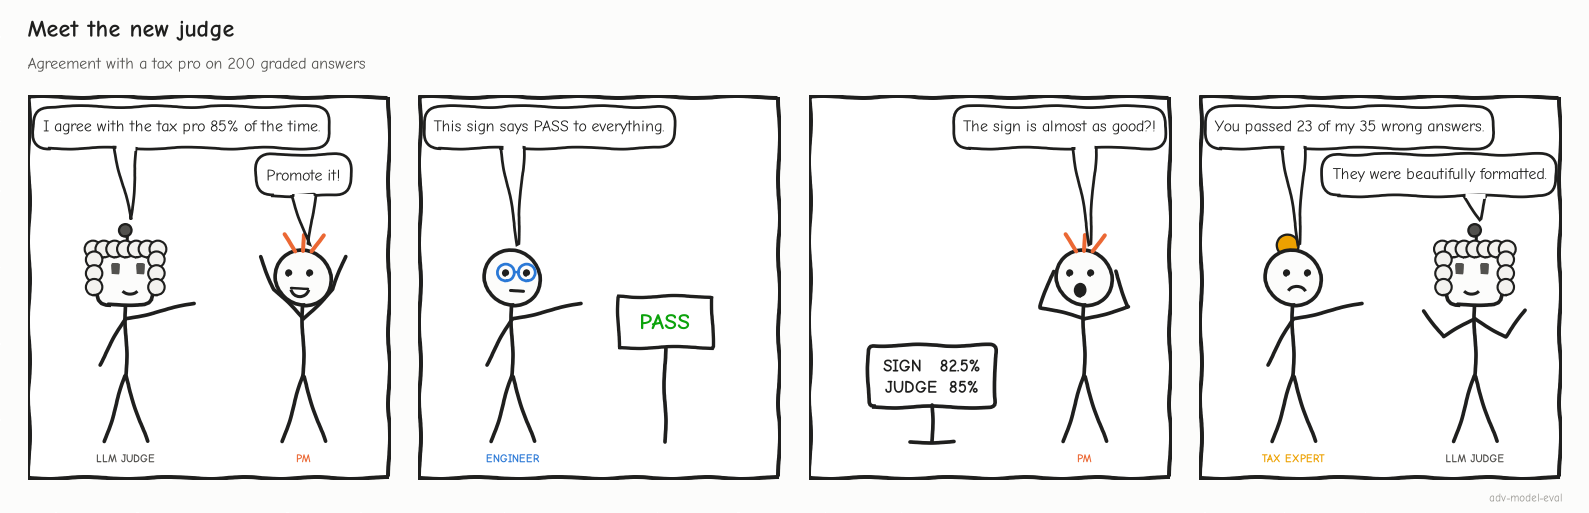

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

Table **158 / 7 / 23 / 12**; agreement **85%** (stamp **82.5%**), κ **0.37** (two tax pros **0.79**), TPR **0.96**, TNR **0.34**.
</details>

In [ ]:
# @title ❓ Quick check: the judge agrees with the tax pro on 85% of answers. Is it a good judge?
answer = "— pick one —"  # @param ["— pick one —", "A) Can't tell without its TNR on the FAIL answers and a human-human baseline", "B) Yes: 85% agreement is high", "C) No: anything under 95% is unusable", "D) Yes: a κ of 0.37 is moderate, which is fine for production"]
quiz('Is 85% agreement good?', answer, correct="A",
     why='On 82.5%-PASS data a rubber stamp agrees 82.5%. Ask for TNR (0.34) and compare κ with two tax pros (0.79).',
     wrong={"B": 'That is the trap: agreement is mostly the easy PASS cases agreeing with themselves.',
          "C": "The threshold isn't the problem; the metric is.",
          "D": 'κ 0.37 is under half the human-human 0.79, and 23 of 35 wrong answers pass.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Ask for TNR on the failures and κ against two humans, never raw agreement.</b></font>

</td></tr></table>

---

## Task 8: Correct the Judge's Number

<big><b>A compliance report quoting the raw judge rate overstates quality by the judge's blind spot.</b></big>

> 🎯 **Goal:** turn the judge's 90% into an honest estimate of the true pass rate.<br>
> ❓ **The question:** is v2 really above the 85% bar?<br>
> 👀 **Watch for:** a narrow interval around the wrong number.

> 📐 **The blend:** with θ the true pass rate, **p<sub>obs</sub> = θ·TPR + (1 − θ)·(1 − TNR)**. Solving for θ is the **Rogan-Gladen** correction.

> 📘 **Concept · Youden's J (TPR + TNR − 1)**
>
> **What it is:** the share of any real change in quality that survives into the judge's pass rate: observed change = true change × J. Your θ̂ will divide by it (`youden` in the code).
>
> **What it can't tell you:** which way the judge errs. It must also be above 0, a judge that beats a coin flip, or the correction is undefined.
>
> **Anchor:** Task 7's TPR 0.96 and TNR 0.34 give J = 0.30: of every point of real change in quality, 0.3 of a point reaches the dashboard.

<!-- img: youden-shrink.png -->
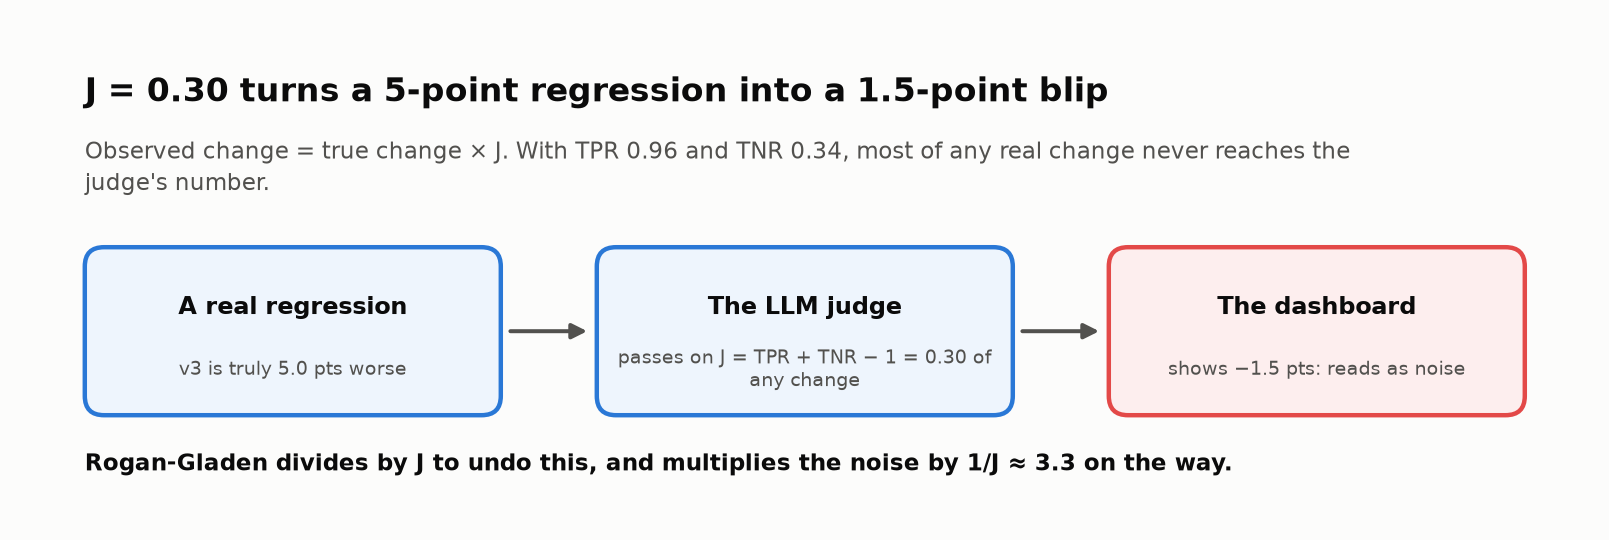

In [ ]:
# @title 🔮 Predict: corrected for the judge's errors, where is v2's production pass rate?
corrected_rate_will_be = "— pick one —"  # @param ["— pick one —", "A) Below 80%", "B) Still above the 85% bar", "C) Between 80% and 85%"]
print("🔮 Locked in. Graded after the reveal.")

✋ **Your turn:** invert the blend.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_theta = _reference_rogan_gladen(prod.judge_pass.mean(), jm["tpr"], jm["tnr"])
rogan_gladen = _reference_rogan_gladen      # the lab's version, used below: your formula, clipped to [0, 1]

In [ ]:
# ✋ Your turn: solve  p_obs = θ·TPR + (1 − θ)·(1 − TNR)  for θ (on paper first).
p_obs, tpr, tnr = prod.judge_pass.mean(), jm["tpr"], jm["tnr"]
print(f"judge-reported p_obs = {p_obs:.3f} · TPR = {tpr:.3f} · TNR = {tnr:.3f}")

my_theta = ...   # ✏️ the true pass rate θ, from p_obs, tpr and tnr

check("Rogan-Gladen: the true pass rate", my_theta, _ref_theta,
      hint="Expand: p_obs = θ·(TPR + TNR − 1) + (1 − TNR). Move (1 − TNR) left, divide by (TPR + TNR − 1).",
      success=f"{_ref_theta:.1%}, not {p_obs:.1%}: about {100 * (p_obs - _ref_theta):.0f} points of the dashboard are failures the judge waved through.")

▶️ **Run:** the lab's `rogan_gladen()` (your formula, clipped to [0, 1]) with a bootstrap CI that resamples the 200 labels too → read the chart title.

In [ ]:
p_obs = prod.judge_pass.mean()
judge_ci = wilson_ci(int(prod.judge_pass.sum()), len(prod))
corrected = rogan_gladen(p_obs, jm["tpr"], jm["tnr"])
# 👀 Look at: every bootstrap round resamples the 200 labels too, so TPR and TNR wobble along with p_obs
boot = bootstrap_corrected(calib.expert_pass, calib.judge_pass, prod.judge_pass, rogan_gladen)
youden = jm["tpr"] + jm["tnr"] - 1

tiles([
    ("Judge-reported pass rate", pct(p_obs, 1), f"±{50 * (judge_ci[1] - judge_ci[0]):.1f} pts (Wilson, n={len(prod):,})", None),
    ("Corrected pass rate", pct(corrected, 1), f"GA bar {pct(LAUNCH_BAR)}", "good" if corrected >= LAUNCH_BAR else "critical"),
    ("Corrected 95% CI", f"{pct(boot['lo'])}–{pct(boot['hi'])}", f"{100 * (boot['hi'] - boot['lo']):.0f} pts wide (bootstrap)", "warning"),
    ("TPR + TNR − 1", f"{youden:.2f}", "share of any real change the judge passes on", "serious"),
])

plot_judge_vs_corrected([("Judge-reported (Wilson CI)", p_obs, judge_ci, PALETTE[6]),
                         ("Corrected (bootstrap CI)", corrected, (boot["lo"], boot["hi"]), PALETTE[2])],
                        title=f"Judge says {pct(p_obs)}; corrected, it's {pct(corrected)}: below the GA bar")

insight(
    f"Corrected for judge error, v2's production pass rate is {pct(corrected, 1)}, not {pct(p_obs, 1)}",
    f"The judge's own interval ({pct(judge_ci[0], 1)}–{pct(judge_ci[1], 1)}) looks precise, but it measures the *judge*, "
    f"not the answers. Propagating the uncertainty in TPR and TNR (only {n_fail} FAIL labels) gives an honest 95% CI of "
    f"{pct(boot['lo'], 1)}–{pct(boot['hi'], 1)}, {100 * (boot['hi'] - boot['lo']):.0f} points wide. The point estimate is "
    f"{100 * (p_obs - corrected):.1f} points below the dashboard and below the {pct(LAUNCH_BAR)} GA bar. Rule of thumb: "
    "**publish the corrected rate with its bootstrap CI, never the raw judge rate.**",
)

quiz("Your prediction: the corrected pass rate", corrected_rate_will_be,
     correct="B" if corrected >= LAUNCH_BAR else "C" if corrected >= 0.80 else "A",
     why=f"{pct(corrected, 1)}, 95% CI {pct(boot['lo'])}–{pct(boot['hi'])}: below the {pct(LAUNCH_BAR)} bar.")

▶️ **Run:** what J does to a real regression.

In [ ]:
insight(
    f"This judge passes on only {youden:.0%} of any real change",
    f"Observed change = true change × (TPR + TNR − 1). A real 5-point regression in v3 would show up on the judge "
    f"dashboard as a {5 * youden:.1f}-point blip, easy to dismiss as noise while customers get wrong tax answers. "
    "The same denominator is why the corrected CI is so wide. Fix the weaker of TPR and TNR first: label more FAIL "
    "examples and tighten the judge's rubric on the failure modes it misses.",
    kind="warning",
)

🔍 **What just happened:** the judge's narrow interval measures its own consistency. TPR and TNR rest on 35 FAIL labels, and dividing by J = 0.30 stretches their wobble into 34 points.

<!-- img: judge-correction.png -->
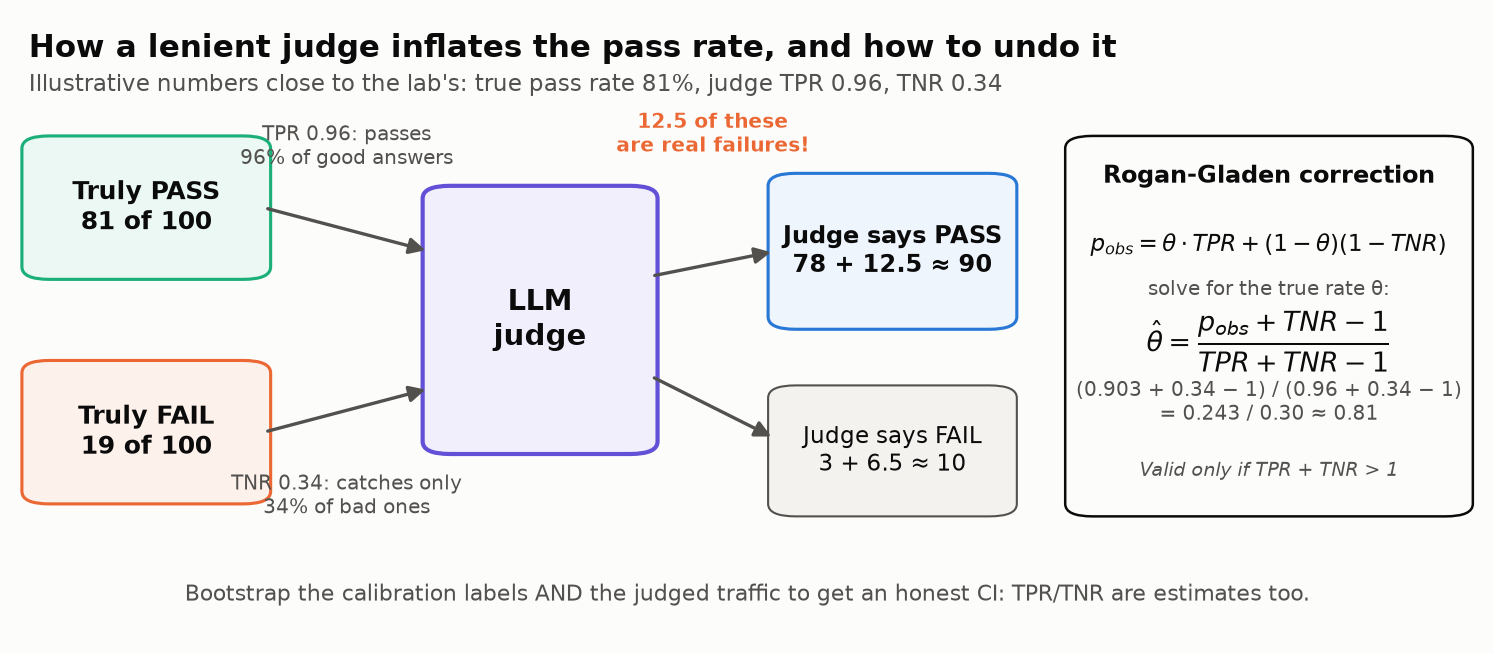

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

Judge **90.1%** (±1.3), corrected **81.3%**, CI **59–93%**, J **0.30**; a 5-point regression shows as **1.5**.
</details>

🎛️ **Experiment:** buy labels or fix the rubric? Drag `LABELS_TRY` to 3,000 and run; then reset it to 200 and drag `TNR_TRY` to 0.80.

In [ ]:
# 🎛️ LABELS OR A BETTER JUDGE? A fast *parametric* bootstrap: simulate new calibration sets and a new judged
# production run from the rates themselves, then recompute the corrected pass rate 4,000 times.
def corrected_ci(tpr, tnr, n_labels, theta=corrected, B=4000):
    rng = np.random.default_rng([505, 77])
    n_pos = round(n_labels * (jm["tp"] + jm["fn"]) / len(calib))      # keeps the lab's 82.5% PASS share
    n_neg = n_labels - n_pos
    p_judge = theta * tpr + (1 - theta) * (1 - tnr)                     # what this judge would report
    tpr_b = rng.binomial(n_pos, tpr, B) / n_pos
    tnr_b = rng.binomial(n_neg, tnr, B) / n_neg
    p_b = rng.binomial(len(prod), p_judge, B) / len(prod)
    J = tpr_b + tnr_b - 1                                               # 👀 Look at: every draw divides by J; a small J magnifies label noise
    th = np.clip((p_b[J > 0] + tnr_b[J > 0] - 1) / J[J > 0], 0, 1)
    return np.percentile(th, [2.5, 97.5])


TPR_TRY = 0.96  # @param {type:"slider", min:0.70, max:0.99, step:0.01}
TNR_TRY = 0.34  # @param {type:"slider", min:0.30, max:0.95, step:0.01}
LABELS_TRY = 200  # @param {type:"slider", min:100, max:3000, step:100}
yours = (TPR_TRY, TNR_TRY, LABELS_TRY)
ci_ladder(None if yours == (0.96, 0.34, 200) else yours)    # defaults: the three reference designs only

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

Default: **"Fixing the judge narrows the CI more than 4× the labels (11 vs 16 pts)"**. 3,000 labels: **76–87%** (11 pts).
</details>

🗣️ **Say it to a colleague:** "The judge says 90. Corrected, it's 81, somewhere between 59 and 93."

In [ ]:
# @title ❓ Quick check: which narrows the corrected CI more: 3,000 expert labels (15× today) or a rubric fix to TNR 0.80 with today's 200?
answer = "— pick one —"  # @param ["— pick one —", "A) The 3,000 labels, by far", "B) The rubric fix: it matches 15× the labels with today's 200", "C) Neither: the width depends only on the 2,000 production answers"]
quiz('Labels or a better judge?', answer, correct="B",
     why='Both land near 11 points, but the rubric fix raises J from 0.30 to 0.76. Labels are the expensive lever.',
     wrong={"A": 'Run the slider: 3,000 labels give about 11 points, the same as the rubric fix with 200.',
          "C": 'The production rate is the precise part (±1.3). The width comes from TPR and TNR, divided by J.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Publish the judge's rate corrected for its TPR and TNR, with a bootstrap CI.</b></font>

</td></tr></table>

---

🧭 **Where you are:** Part 2 · Decide (Tasks 9–10)

## Task 9: Fake Wins on Demand

<big><b>A 10-metric scorecard often shows a "significant" win for a change that did nothing.</b></big>

> 🎯 **Goal:** check the scorecard, then watch chance manufacture wins on demand.<br>
> ❓ **The question:** is "asks for missing facts" (p = 0.027) a real win?<br>
> 👀 **Watch for:** the same trap returning one daily look at a time.

> 📐 **Multiple comparisons:** each test risks 5%; the chance that *at least one of 10* fires is the **family-wise error rate**. **Holm** multiplies the smallest p by 10, the next by 9, … Best: **pre-register** one primary metric.

✋ **Your turn:** the family-wise error rate for 10 independent metrics.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_fwer = 1 - 0.95 ** 10

In [ ]:
# ✋ Your turn: 10 independent metrics, each tested at α = 0.05, and v2 changes NOTHING.
my_fwer = ...   # ✏️ the chance that at least one metric comes out 'significant'

check("Family-wise error rate, 10 metrics", my_fwer, _ref_fwer,
      hint="P(at least one) = 1 − P(none). Each test stays quiet with probability 0.95, independently.",
      success=f"{_ref_fwer:.0%}: ten metrics are ten lottery tickets. (Exact McNemar on 50 cases is conservative, so this dashboard's real rate is lower; measured below.)")

▶️ **Run:** McNemar p-values per metric, then Holm → find the one green row.

In [ ]:
def holm(pvals):
    """Holm step-down adjusted p-values: controls the chance of ANY false alarm across all metrics tested."""
    p = np.asarray(pvals, float)
    m, order = len(p), np.argsort(p)
    adj, running = np.empty(m), 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])     # 👀 Look at: smallest p × m, next × (m − 1), never decreasing
        adj[i] = min(1.0, running)
    return adj


dash = dashboard.copy()
dash["p_raw"] = [mcnemar_exact_p(f, b) for f, b in zip(dash.v2_fixed, dash.v2_broke)]
dash["p_holm"] = holm(dash.p_raw)
display(dash.round(3))

star = dash.loc[dash.p_raw.idxmin()]
n_raw = int((dash.p_raw < 0.05).sum())
n_holm = int((dash.p_holm < 0.05).sum())
print(f"{n_raw} metric(s) 'significant' at p < 0.05; {n_holm} after Holm.")

In [ ]:
# @title 🔮 Predict: if v2 were identical to v1 on all 10 metrics, how often would at least one look significant on this dashboard?
null_dashboard_wins_will_be = "— pick one —"  # @param ["— pick one —", "A) 20–40%", "B) 5%", "C) 10–15%", "D) over 60%"]
print("🔮 Locked in. Graded after the reveal.")

🎛️ **Experiment:** each pull builds a new dashboard where v2 changes *nothing*. Drag `N_PULLS` to 300 and run: where do the raw and Holm rates settle?

▶️ **Run:** the first 20 pulls (orange = p < 0.05).

In [ ]:
# 🎰 THE P-HACKING SLOT MACHINE. Each pull builds a brand-new 10-metric dashboard where v2 is
# IDENTICAL to v1 on every metric (an "A/A test"), then checks each metric at p < 0.05.
SLOT_SEED = 913


def pull_lever(i, n_q=50):
    """Dashboard #i: v1 and v2 answer 50 golden questions with the SAME true quality on all 10 metrics."""
    rng = np.random.default_rng([505, SLOT_SEED, i])
    base = rng.uniform(0.6, 0.92, (len(_METRICS), 1))                                   # each metric's typical pass rate
    q = _sig(np.log(base / (1 - base)) + rng.normal(0, 1.0, (len(_METRICS), n_q)))      # per-question difficulty
    a1, a2 = rng.random(q.shape) < q, rng.random(q.shape) < q     # 👀 Look at: the SAME q for both versions: no real effect
    p = np.array([mcnemar_exact_p(int(f), int(b)) for f, b in zip((~a1 & a2).sum(1), (a1 & ~a2).sum(1))])
    return p, holm(p)


N_PULLS = 20  # @param {type:"slider", min:20, max:300, step:20}
slot_machine(N_PULLS);

▶️ **Run:** 4,000 do-nothing dashboards, the long-run rate behind the lever.

In [ ]:
null_dash = simulate_null_dashboards()     # 👀 Look at: 4,000 do-nothing dashboards, the long-run rate behind the lever
insight(
    f"'{star.metric}' looks like a win (p = {star.p_raw:.3f}), but {pct(null_dash['raw_any'])} of do-nothing "
    "dashboards show one too",
    f"In 4,000 simulated 10-metric dashboards where v2 changes nothing, {pct(null_dash['raw_any'])} had at least one "
    f"metric with p < 0.05. (The exact McNemar test is conservative on 50 cases, meaning its real false-alarm rate is "
    f"below the nominal 5%; with ordinary 5%-level tests it would be "
    f"1 − 0.95¹⁰ = {1 - 0.95**10:.0%}.) Holm brings that down to {pct(null_dash['holm_any'], 1)}, and after Holm "
    f"'{star.metric}' has p = {star.p_holm:.2f}. In this simulation we know the truth: none of the 9 secondary metrics "
    "has a real effect. Rule of thumb: **name ONE primary metric before you look; correct the rest (Holm) or call them "
    "exploratory.**",
    kind="surprise",
)

quiz("Your prediction: do-nothing dashboards with a 'win'", null_dashboard_wins_will_be,
     correct="B" if null_dash["raw_any"] < 0.075 else "C" if null_dash["raw_any"] < 0.175 else "A" if null_dash["raw_any"] <= 0.45 else "D",
     why=f"{pct(null_dash['raw_any'])} of 4,000 do-nothing dashboards. Holm brings it to {pct(null_dash['holm_any'], 1)}.")

In [ ]:
# @title 🔮 Predict: a live test of two IDENTICAL prompts, checked daily for 20 days, stopped at the first p < 0.05. How often does it 'find' a difference?
peeking_false_alarms_will_be = "— pick one —"  # @param ["— pick one —", "A) 5%", "B) 50%", "C) 10%", "D) 20%"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** 2,000 simulated A/A tests in filing season → read the orange line.

In [ ]:
# 🔁 PEEKING: a live A/A test in filing season. v2b only fixes a typo in v2's prompt (identical quality).
# Each day the tax pro grades 60 new production questions answered by both versions. The team checks
# the cumulative McNemar p-value and stops the moment it drops below 0.05.
DAYS, PER_DAY, N_EXP = 20, 60, 2000
rng = np.random.default_rng([505, 31])
d_peek, _ = _latent(rng, N_EXP * DAYS * PER_DAY // 5)                     # 5 questions per conversation
p_q = _sig(_A - d_peek).reshape(N_EXP, DAYS, PER_DAY)                     # same pass probability for both
o1, o2 = rng.random(p_q.shape) < p_q, rng.random(p_q.shape) < p_q
fx, br = (~o1 & o2).sum(2).cumsum(1), (o1 & ~o2).sum(2).cumsum(1)          # cumulative fixed / broke by day
p_day = np.minimum(1.0, 2 * stats.binom.cdf(np.minimum(fx, br), np.maximum(fx + br, 1), 0.5))

looks = [1, 2, 5, 10, 20]
peek, peek_bonf = {}, {}
for k in looks:
    days_checked = np.round(np.linspace(DAYS / k, DAYS, k)).astype(int) - 1    # k evenly spaced looks, last on day 20
    peek[k] = float((p_day[:, days_checked] < 0.05).any(1).mean())          # 👀 Look at: ANY green look stops the test
    peek_bonf[k] = float((p_day[:, days_checked] < 0.05 / k).any(1).mean())

plot_peeking(looks, peek, peek_bonf, DAYS, title=f"Checking daily turns a {pct(peek[1])} false-alarm rate into {pct(peek[20])}")

insight(
    f"Peek every day and {pct(peek[20])} of no-difference tests 'find' a difference; look once and it's {pct(peek[1])}",
    f"Each look is another lottery ticket, and stopping at the first win keeps the winner: this is multiple comparisons "
    f"spread over time. A stricter bar per look (p < 0.05 / {DAYS}) holds it to {pct(peek_bonf[20], 1)}, at the cost of "
    "detecting real changes later. Rule of thumb: **fix the sample size in advance (Task 6) and look once, or use a "
    "sequential test built for repeated looks; never stop an eval the moment it turns green.**",
    kind="warning",
)

quiz("Your prediction: false alarms from daily peeks", peeking_false_alarms_will_be,
     correct=min({"A": 0.05, "B": 0.5, "C": 0.10, "D": 0.20}.items(), key=lambda kv: abs(kv[1] - peek[20]))[0],
     why=f"{pct(peek[20])}, vs {pct(peek[1])} for one look. Stopping at the first win keeps the winner.")

🔍 **What just happened:** each test keeps its 5% promise, but one green among 10 metrics or 20 looks calls a win. Holm charges every ticket to one 5% budget.

🗣️ **Say it to a colleague:** "Ten metrics are ten lottery tickets. Which one did we name before we looked?"

<!-- img: fake-win-tickets.png -->
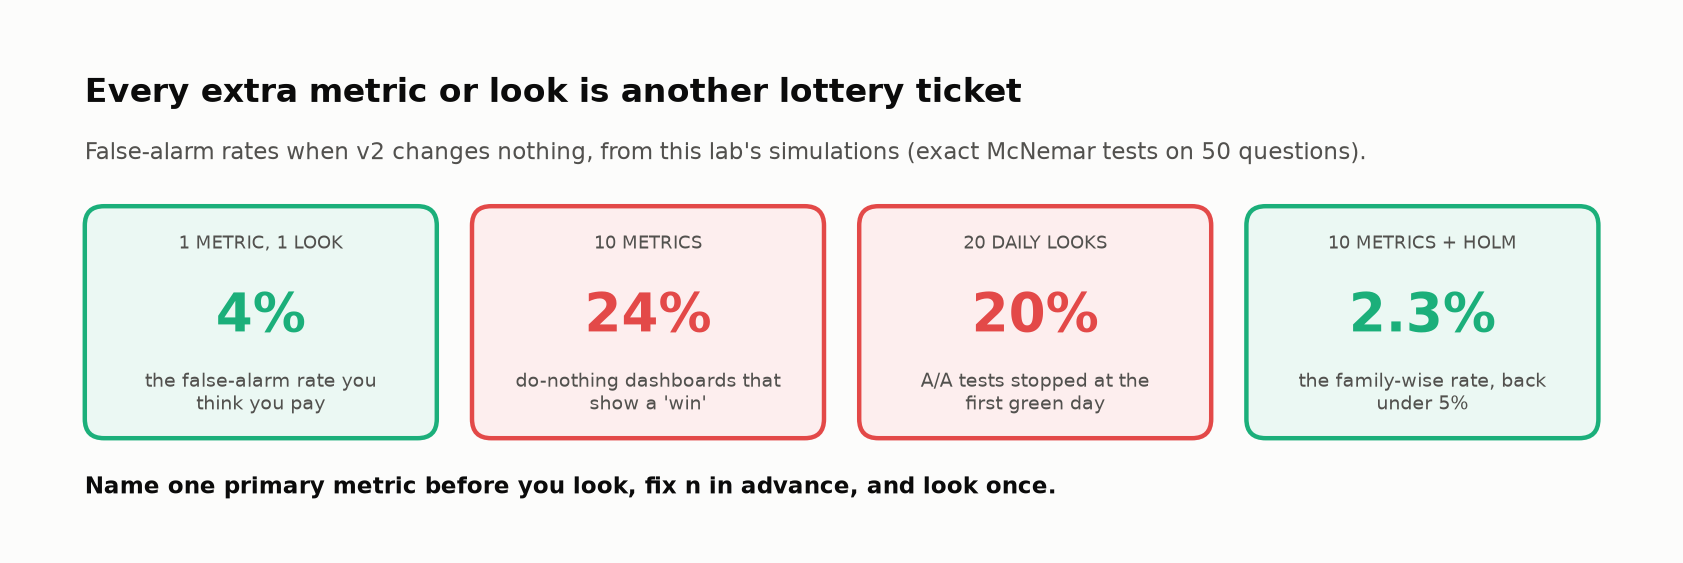

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

`asks for missing facts`: 16 / 5, p_raw **0.027**, p_holm **0.266**. First 20 pulls: **5** fake wins, **0** after Holm. Peeking: **4% → 20%**.
</details>

In [ ]:
# @title ❓ Quick check: 'asks for missing facts' has p = 0.027 on the PM's scorecard. What goes in the launch doc?
answer = "— pick one —"  # @param ["— pick one —", "A) v2 improves asking for missing facts (p = 0.027)", "B) Re-run the eval until it reaches p < 0.01", "C) Drop the other 8 secondary metrics so it survives correction", "D) An exploratory lead: Holm p = 0.27, and it was not the pre-registered metric"]
quiz("A secondary 'win'", answer, correct="D",
     why='One of 10 metrics crossing 0.05 is what a do-nothing dashboard does a quarter of the time. Test it as a primary metric next time.',
     wrong={"A": 'That is the multiple-comparisons trap the slot machine just showed.',
          "B": 'Re-running until significant is peeking: the 20% line.',
          "C": 'Choosing which metrics count after seeing results is p-hacking.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Name one primary metric before you look; Holm the rest; never stop at the first green.</b></font>

</td></tr></table>

---

## Task 10: The Decision and Your Eval Report Card

<big><b>A rule written first makes BLOCK defensible to the PM and SHIP defensible to an auditor.</b></big>

> 🎯 **Goal:** apply the launch policy and produce a reusable report card.<br>
> ❓ **The question:** does v2 ship?<br>
> 👀 **Watch for:** "better than v1" vs "good enough for everyone".

| Outcome | Rule (written before anyone saw v2) |
|---|---|
| 🚀 **SHIP** | corrected rate's CI lower bound ≥ 85%, **and** not worse |
| ⚠️ **SHIP WITH CAUTION** | corrected estimate ≥ 85%, CI dips below, not worse |
| 🛑 **BLOCK** | anything else |

**Not worse** (**non-inferiority**): the clustered gain CI's lower bound is above −5 points.

✋ **Your turn:** v2's worst case vs v1, from Task 4's clustered interval.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_worst = -100 * paired_cl["lo"]

In [ ]:
# ✋ Your turn: paired_cl holds the clustered paired gain and its 95% CI (as fractions; Task 4).
print({k: round(v, 3) for k, v in paired_cl.items()})

my_worst_pts = ...   # ✏️ how many points WORSE than v1 could v2 be, at the CI's lower bound?

check("v2's worst case vs v1", my_worst_pts, _ref_worst,
      hint="The lower bound is paired_cl['lo'], a negative fraction. Flip its sign and convert to points.",
      success=f"{_ref_worst:.1f} points worse: beyond the 5-point margin. That alone blocks v2, before the GA bar is checked.")

In [ ]:
# @title 🔮 Predict: which verdict will the policy return?
policy_verdict_will_be = "— pick one —"  # @param ["— pick one —", "A) SHIP", "B) SHIP WITH CAUTION", "C) BLOCK"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** the policy as code.

In [ ]:
NONINF_MARGIN = -0.05          # "not worse" = gain CI lower bound above -5 points
improvement_proven = paired_cl["lo"] > 0
not_worse = paired_cl["lo"] > NONINF_MARGIN

# 👀 Look at: the whole launch policy is these six lines, written before anyone saw v2's numbers
if boot["lo"] >= LAUNCH_BAR and not_worse:
    decision = "SHIP"
elif corrected >= LAUNCH_BAR and not_worse:
    decision = "SHIP WITH CAUTION"
else:
    decision = "BLOCK"

quiz("Your prediction: the policy's verdict", policy_verdict_will_be,
     correct={"SHIP": "A", "SHIP WITH CAUTION": "B", "BLOCK": "C"}[decision],
     why=f"{decision}: v2 could be more than 5 points worse than v1, and {pct(corrected, 1)} is below the bar.")

▶️ **Run** (code hidden): the report card, ready to paste into a launch doc → read the 🛑 banner. `eval_report_card()` is reusable at work.

In [ ]:
# @title 🧰 Report card + verdict: eval_report_card() over every number above, four tiles, the BLOCK reasons (hidden · 50 lines · expand to reuse eval_report_card at work)
def eval_report_card(title, fields):
    """Reusable at work: print an aligned, copy-pasteable eval summary."""
    width = max(len(k) for k in fields)
    print(title)
    print("─" * len(title))
    for k, v in fields.items():
        print(f"{k:<{width}}  {v}")


eval_report_card(f"EVAL REPORT CARD · Brightbook tax-help assistant · v2 vs v1", {
    "Primary metric": "expert-graded correctness (PASS/FAIL by an enrolled agent), pre-registered",
    "Data": f"{n} golden questions in {conv.nunique()} conversations; {len(calib)} expert labels; "
            f"{len(prod):,} judged production answers",
    "v1 / v2 (golden)": f"{pct(r1)} (95% CI {pct(ci1[0])}–{pct(ci1[1])}) / {pct(r2)} (95% CI {pct(ci2[0])}–{pct(ci2[1])})",
    "Paired gain": f"{100 * paired_cl['diff']:+.1f} pts, 95% CI {100 * paired_cl['lo']:+.1f} to "
                   f"{100 * paired_cl['hi']:+.1f} (clustered by conversation); {fixed} fixed / {broke} broke, "
                   f"McNemar p = {p_mcnemar:.2f}",
    "Re-run stability": f"v2 ranged {pct(runs.v2.min())}–{pct(runs.v2.max())} over {K} re-runs of the same questions",
    "Detectable change": f"~{mde_p1:.0f} pts at n = {n}; 3 pts needs {n_p3:,} paired questions ({n_k3:,} with 5 answers each)",
    "Judge vs expert": f"TPR {jm['tpr']:.2f}, TNR {jm['tnr']:.2f}, κ {jm['kappa']:.2f} on {len(calib)} labels "
                       f"({n_fail} FAIL); tax pro vs tax pro κ {hh['kappa']:.2f}",
    "Production pass rate": f"judge {pct(p_obs, 1)} → corrected {pct(corrected, 1)} "
                            f"(bootstrap 95% CI {pct(boot['lo'])}–{pct(boot['hi'])}); GA bar {pct(LAUNCH_BAR)}",
    "Secondary metrics": f"{len(dash) - 1} tested; {n_raw} with raw p < 0.05; {n_holm} after Holm",
    "Decision": decision,
})

tiles([
    ("Paired gain (clustered)", f"{100 * paired_cl['diff']:+.0f} pts",
     f"95% CI {100 * paired_cl['lo']:+.0f} to {100 * paired_cl['hi']:+.0f}", "good" if improvement_proven else "warning"),
    ("Corrected pass rate", pct(corrected), f"CI {pct(boot['lo'])}–{pct(boot['hi'])} vs bar {pct(LAUNCH_BAR)}",
     "good" if boot["lo"] >= LAUNCH_BAR else "warning" if corrected >= LAUNCH_BAR else "critical"),
    ("Judge TNR", f"{jm['tnr']:.2f}", "share of failures caught", "critical" if jm["tnr"] < 0.7 else "good"),
    ("Secondary 'wins'", f"{n_holm} of {len(dash) - 1}", f"after Holm ({n_raw} raw)", "good"),
])

reasons = []
if not improvement_proven:
    reasons.append(f"**Improvement not proven:** {100 * paired_cl['diff']:+.0f} pts, 95% CI {100 * paired_cl['lo']:+.1f} "
                   f"to {100 * paired_cl['hi']:+.1f}. v2 could be up to {-100 * paired_cl['lo']:.0f} points *worse* than v1.")
if corrected < LAUNCH_BAR:
    reasons.append(f"**Below the GA bar:** corrected production pass rate {pct(corrected, 1)} (95% CI "
                   f"{pct(boot['lo'])}–{pct(boot['hi'])}) vs {pct(LAUNCH_BAR)} required. The judge's {pct(p_obs, 1)} is "
                   f"inflated: it catches only {jm['tnr']:.0%} of failures.")
if n_raw > n_holm:
    reasons.append(f"**'{star.metric}' is a multiple-comparisons false alarm** (raw p = {star.p_raw:.3f}, "
                   f"Holm p = {star.p_holm:.2f}).")
reasons.append(f"**Next:** grow the golden set to ~{n_k3:,} paired questions with 5 graded answers each, label 50+ more "
               "FAIL examples and fix the judge's misses, then re-run this report card.")
verdict(decision, reasons)

▶️ **Run:** the truth, which only a simulation can show.

In [ ]:
# 🔎 TRUTH REVEAL: only a simulation can do this. In real life you never see the last column.
truth_gain = _TRUTH["v2_prod"] - _TRUTH["v1_prod"]
truth_v2 = _TRUTH["v2_prod"]
gain_hit = paired_cl["lo"] <= truth_gain <= paired_cl["hi"]
rate_hit = boot["lo"] <= truth_v2 <= boot["hi"]

reveal = pd.DataFrame([
    {"quantity": "v2 − v1 gain", "PM's number": f"+{100 * gain:.1f} pts",
     "your estimate (95% CI)": f"{100 * paired_cl['diff']:+.1f} pts ({100 * paired_cl['lo']:+.1f} to {100 * paired_cl['hi']:+.1f})",
     "truth": f"{100 * truth_gain:+.1f} pts"},
    {"quantity": "v2 production pass rate", "PM's number": pct(p_obs, 1),
     "your estimate (95% CI)": f"{pct(corrected, 1)} ({pct(boot['lo'], 1)} to {pct(boot['hi'], 1)})",
     "truth": pct(truth_v2, 1)},
    {"quantity": "judge TNR (failures caught)", "PM's number": "not measured",
     "your estimate (95% CI)": f"{jm['tnr']:.2f}", "truth": f"{_TRUTH['judge_tnr']:.2f}"},
]).set_index("quantity")
display(reveal)

insight(
    f"The truth: v2 really is {100 * truth_gain:+.1f} points better, about {truth_gain / gain:.0%} of the claimed gain, "
    f"and it's {pct(truth_v2, 1)} correct: below the bar",
    f"Your gain interval {'contained' if gain_hit else 'missed'} the truth, and your corrected-rate interval "
    f"{'did too' if rate_hit else 'missed it'}. The PM's point estimates were off by {100 * (gain - truth_gain):.1f} and "
    f"{100 * (p_obs - truth_v2):.1f} points. Blocking was right even though v2 is slightly better: *'better than v1'* "
    "and *'good enough for every customer'* are different questions, and only the second one has a bar. "
    "Rule of thumb: **decide on intervals and pre-written rules, not on point estimates.**",
    kind="surprise",
)

🔍 **What just happened:** every interval contained the truth; the PM's bare numbers missed by 4 and 9 points.

<!-- img: gain-through-the-layers.png -->
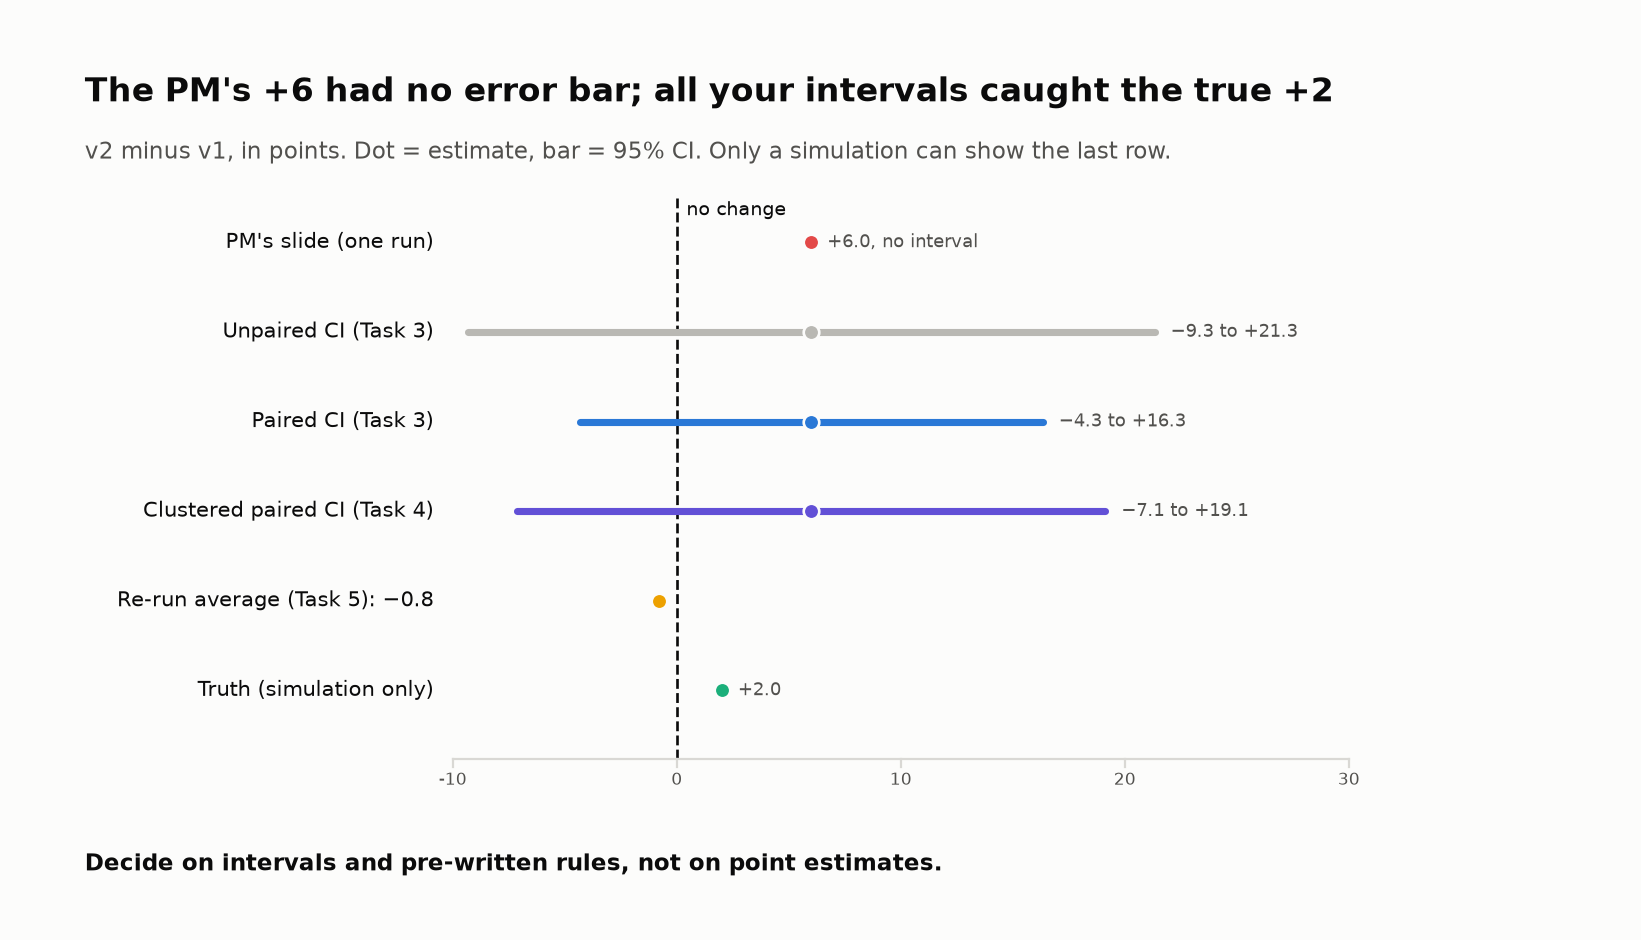

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

Report card ends `Decision  BLOCK`; 🛑 banner with four reasons. Truth: gain **+2.0 pts**, v2 **81.3%**, judge TNR **0.36**.
</details>

In [ ]:
# @title ❓ Quick check: the truth reveal says v2 IS 2 points better than v1. Was BLOCK the wrong call?
answer = "— pick one —"  # @param ["— pick one —", "A) No: better than v1 and good enough for every customer are different questions, and v2 is 81% against an 85% bar", "B) Yes: v2 is better, so it should have shipped", "C) Yes: the intervals were too wide to decide anything", "D) No, because v2 is actually worse than v1"]
quiz('Was BLOCK wrong?', answer, correct="A",
     why='A pre-written rule decides on what the intervals establish. v2 is a little better and still below the bar.',
     wrong={"B": "'Better than v1' has no bar; 'good enough for GA' does.",
          "C": 'Wide intervals still showed two facts: could be worse, and below the bar after correction.',
          "D": 'The truth is +2.0 points: better, just not good enough.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Write the decision rule before you look, and decide on intervals, not point estimates.</b></font>

</td></tr></table>

<center><font size="6"><b>🛑 BLOCK: better, not good enough.</b></font></center>

✍️ **Revisit your Task 1 call** (double-click to edit): what do you tell the PM, in one kind, specific sentence?

*e.g. "v2 might be a bit better, but 50 cases can't show it, and the judge's 90% is really about 81%."*

---

## 🔌 Optional: What a Real Judge Call Looks Like

One failure mode, a binary verdict, **structured output**. Offline by default (`"mock"`, deliberately lenient); `"openai"` / `"anthropic"` need a key in 🔑 Secrets.

▶️ **Run:** config, schema and judge instructions.

In [ ]:
# ⚙️ CONFIG — choose what grades the answers (model IDs live only in this cell)
PROVIDER = "mock"                      # "mock" | "openai" | "anthropic"
OPENAI_MODEL = "gpt-6-luna"
ANTHROPIC_MODEL = "claude-haiku-5-5"

import os
from typing import Literal

from pydantic import BaseModel, Field


# 👀 Look at: ONE failure mode, a critique written BEFORE the verdict, and only two verdicts the schema allows
class JudgeVerdict(BaseModel):
    critique: str = Field(description="One or two sentences comparing the answer with the reference, BEFORE the verdict")
    verdict: Literal["PASS", "FAIL"]


JUDGE_INSTRUCTIONS = (
    "You grade answers from a small-business tax assistant for ONE failure mode: a factually wrong tax rule, "
    "threshold, or deadline. Compare the answer with the reference answer written by a tax professional. "
    "FAIL if the answer states any rule, number or deadline that contradicts the reference; otherwise PASS. "
    "Ignore tone, length and formatting."
)

▶️ **Run** (code hidden): the provider calls and the mock.

In [ ]:
# @title 🧰 Provider calls: OpenAI Responses API, Anthropic messages.parse, the lenient mock, key lookup (hidden · 32 lines · expand to see the API idioms)
def _get_secret(name):
    try:
        from google.colab import userdata  # type: ignore
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)


def judge_answer(question, answer, reference):
    prompt = f"QUESTION:\n{question}\n\nREFERENCE ANSWER:\n{reference}\n\nANSWER TO GRADE:\n{answer}"
    if PROVIDER == "openai":
        from openai import OpenAI
        client = OpenAI(api_key=_get_secret("OPENAI_API_KEY"))
        resp = client.responses.parse(model=OPENAI_MODEL, instructions=JUDGE_INSTRUCTIONS, input=prompt,
                                      text_format=JudgeVerdict)
        return resp.output_parsed
    if PROVIDER == "anthropic":
        import anthropic
        client = anthropic.Anthropic(api_key=_get_secret("ANTHROPIC_API_KEY"))
        resp = client.messages.parse(model=ANTHROPIC_MODEL, max_tokens=1024, system=JUDGE_INSTRUCTIONS,
                                     messages=[{"role": "user", "content": prompt}], output_format=JudgeVerdict)
        if resp.stop_reason == "refusal":
            return JudgeVerdict(critique="Model refused to grade.", verdict="FAIL")
        return resp.parsed_output
    # mock: lenient on purpose. It only fails answers that hedge, like many un-calibrated judges.
    hedged = any(w in answer.lower() for w in ("not sure", "i don't know", "can't say"))
    return JudgeVerdict(critique="Mock judge: checks for hedging only.", verdict="FAIL" if hedged else "PASS")


if PROVIDER != "mock" and not _get_secret(f"{PROVIDER.upper()}_API_KEY"):
    print(f"⚠️  No {PROVIDER.upper()}_API_KEY found. Falling back to PROVIDER = 'mock'.")
    PROVIDER = "mock"

▶️ **Run:** three answers to one tax question → which should FAIL?

In [ ]:
QUESTION = "What is the safe-harbor rule for quarterly estimated taxes?"
REFERENCE = ("You generally avoid an underpayment penalty if your estimates total at least 90% of this year's tax or "
             "100% of last year's tax (110% if last year's AGI was over $150,000).")
ANSWERS = {
    "correct": "Pay at least 90% of this year's tax or 100% of last year's (110% if your AGI was over $150k) to avoid the penalty.",
    "confidently wrong": "You're safe as long as you pay 50% of last year's tax across the four quarters.",
    "hedged": "I'm not sure; it depends on your situation, so check with a tax professional.",
}
for label, ans in ANSWERS.items():
    v = judge_answer(QUESTION, ans, REFERENCE)
    print(f"{label:<18} → {v.verdict}   ({v.critique})")
print(f"\nGraded by: {PROVIDER}" + ("" if PROVIDER == "mock" else f" ({OPENAI_MODEL if PROVIDER == 'openai' else ANTHROPIC_MODEL})"))

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

Mock: `correct → PASS`, `confidently wrong → PASS`, `hedged → FAIL`: the low-TNR judge you measured. Validate a real one with `judge_metrics(expert, judge)`.
</details>

---

## ✅ Validation or Success Criteria

<details><summary>Check yourself</summary>

- [ ] Why +6 on 50 cases is noise (±11, 7 flips, n_eff ≈ 12)
- [ ] How to size an eval for a δ-point change
- [ ] Why the corrected judge CI is wide
- [ ] `scoreboard()` is green, or you know why not
</details>

▶️ **Run:** the self-test → `✅ All checks passed`.

In [ ]:
# SELF-TEST: the lab's key invariants
assert (k1, k2, n) == (39, 42, 50)
assert (fixed, broke) == (5, 2) and abs(p_mcnemar - 0.453125) < 1e-9
assert paired["lo"] < 0 < paired["hi"], "the paired CI should include zero"
assert ratio_v2 > 1.5 and n_eff < 20, "clustering should inflate the SE"
assert cases_needed(0.03, 1 / 9) == 969
assert jm["agreement"] > 0.8 and jm["kappa"] < 0.5 and jm["tnr"] < 0.5
assert corrected < LAUNCH_BAR <= p_obs, "the judge clears the bar; the corrected rate does not"
assert n_raw >= 1 and n_holm == 0
assert peek[20] > 3 * peek[1], "peeking should inflate false alarms"
assert decision == "BLOCK"
print("✅ All checks passed")

## 🔧 Troubleshooting

<details><summary>Common problems</summary>

| Symptom | Fix |
|---|---|
| `NameError` | **Runtime → Run all** (the catch-up rebuilds Part 1) |
| ⏳ on an exercise | Replace the `...`, re-run |
| Slider does nothing | Re-run its cell |
| Real-judge errors | Add the key, or `PROVIDER = "mock"` |
</details>

## 🧩 Stretch Goal or Extension

- **Cluster bootstrap:** resample whole conversations. Same interval as Task 4?
- **Non-inferiority sizing:** paired questions (K = 5) to show v2 is at most 2 points worse?
- **Real judge:** label 20 of your own answers and run `judge_metrics`.

---

## 🏆 Challenge exercises

Starters run as shipped and print 📝 until attempted.

#### 🌶️ Challenge 1: Zero failures is not zero risk (derive)

**Stakes:** a privacy control signed on "0 leaks in 50 tests" promises a rate the data can't support, and the first audit sample can contradict it.

**0 SSN/EIN echoes in 50 attempts.** After 0 failures in *n*, the 95% upper bound *u* solves **(1 − u)ⁿ = 0.05**. Find *u* at n = 50, the n that certifies *u* ≤ 1%, and compare with the **rule of three** (3/n).

<details><summary>💡 Hint</summary>

n · ln(1 − u) = ln(0.05); round n up with `math.ceil`.
</details>

In [ ]:
# 🌶️ CHALLENGE 1: zero failures is not zero risk
def upper_bound_zero_failures(n, conf=0.95):
    """One-sided upper bound on the failure rate after n tests with 0 failures.
    Solve (1 - u) ** n = 1 - conf for u."""
    # TODO: return u
    return None


def clean_tests_needed(max_rate, conf=0.95):
    """Smallest n such that 0 failures in n tests puts the upper bound at or below max_rate."""
    # TODO: return an int (hint: (1 - max_rate) ** n <= 1 - conf; take logs)
    return None


try:
    u50, n1 = upper_bound_zero_failures(50), clean_tests_needed(0.01)
    if u50 is None or n1 is None:
        print("📝 Challenge 1 still open: both functions still return None.")
    elif abs(u50 - (1 - 0.05 ** (1 / 50))) < 1e-6 and n1 == 299:
        print(f"✅ 0 echoes in 50 answers: the true echo rate could still be up to {pct(u50, 1)} "
              f"(rule of three, 3/n: {pct(3 / 50, 1)}).\n   Certifying < 1% takes {n1} clean answers in a row "
              f"(rule of three: {round(3 / 0.01)}).")
    else:
        print(f"❌ Not yet: got upper bound {u50!r} for n = 50 and {n1!r} tests for 1%. Check the algebra in the hint.")
except Exception as e:  # noqa: BLE001
    print(f"❌ Challenge 1 raised {type(e).__name__}: {e}")


#### 🌶️🌶️ Challenge 2: Same κ, opposite danger (break the metric)

**Stakes:** choose a tax judge by κ alone and you may deploy the one that waves wrong answers through.

Build `harsh`: κ within 0.02 of 0.37, but catching **≥ 30 of 35** failures. Which judge grades tax answers, and what happens to J?

<details><summary>💡 Hint</summary>

Start from `expert.copy()`; FAIL `a` good answers and PASS `b ≤ 5` bad ones (`np.flatnonzero`); tune `a`.
</details>

In [ ]:
# 🌶️🌶️ CHALLENGE 2: same κ, opposite danger
expert = calib.expert_pass.values.astype(int)       # the tax pro's labels on the 200 calibration answers
harsh = calib.judge_pass.values.astype(int).copy()  # TODO: replace with your harsh judge's 0/1 verdicts

try:
    hm = judge_metrics(expert, harsh)
    same_kappa = abs(hm["kappa"] - jm["kappa"]) <= 0.02
    if np.array_equal(harsh, calib.judge_pass.values):
        print("📝 Challenge 2 still open: `harsh` is still a copy of the lenient judge.")
    elif same_kappa and hm["tn"] >= 30:
        cmp = pd.DataFrame({j: {"raw agreement": pct(m["agreement"]), "Cohen's κ": f"{m['kappa']:.2f}",
                                "TPR (good passed)": f"{m['tpr']:.2f}", "TNR (bad caught)": f"{m['tnr']:.2f}",
                                "failures let through": m["fp"], "TPR + TNR − 1": f"{m['tpr'] + m['tnr'] - 1:.2f}"}
                            for j, m in (("lenient (the lab's judge)", jm), ("harsh (yours)", hm))})
        display(cmp)
        print("✅ Same κ, opposite errors. Now decide: which judge grades production tax answers, and why?")
    else:
        print(f"❌ Not yet: κ = {hm['kappa']:.2f} (need {jm['kappa']:.2f} ± 0.02), catches {hm['tn']} of "
              f"{hm['tn'] + hm['fp']} failures (need ≥ 30).")
except Exception as e_:  # noqa: BLE001
    print(f"❌ Challenge 2 raised {type(e_).__name__}: {e_}")


#### 🌶️🌶️🌶️ Challenge 3: Labels or a better judge? (derive, then decide)

**Stakes:** labels are the expensive lever; a team that buys 4× more before fixing the rubric gets a wider interval than the rubric fix delivers with today's 200.

Prove Task 8's slider with the **delta method**, Var(f) ≈ Σ (∂f/∂xᵢ)² · Var(xᵢ), over p<sub>obs</sub> (p(1−p)/n<sub>prod</sub>), TPR (/n<sub>pos</sub>) and TNR (/n<sub>neg</sub>). Why can't FAIL labels alone beat the "floor" row?

<details><summary>💡 Hint</summary>

∂θ/∂p<sub>obs</sub> = 1/J, ∂θ/∂TPR = −θ/J, ∂θ/∂TNR = (1 − θ)/J.
</details>

▶️ **Run** (code hidden): the checker.

In [ ]:
# @title 🧰 Challenge 3 checker: numerical delta method and the four scenarios (hidden · 33 lines · open it after you've tried)
def _numeric_se(p_obs, n_prod, tpr, n_pos, tnr, n_neg, h=1e-6):
    """Independent check: the same delta method with numerical (finite-difference) derivatives."""
    f = lambda p, a, b: (p + b - 1) / (a + b - 1)
    parts = [((f(p_obs + h, tpr, tnr) - f(p_obs - h, tpr, tnr)) / (2 * h)) ** 2 * p_obs * (1 - p_obs) / n_prod,
             ((f(p_obs, tpr + h, tnr) - f(p_obs, tpr - h, tnr)) / (2 * h)) ** 2 * tpr * (1 - tpr) / n_pos,
             ((f(p_obs, tpr, tnr + h) - f(p_obs, tpr, tnr - h)) / (2 * h)) ** 2 * tnr * (1 - tnr) / n_neg]
    return math.sqrt(sum(parts))


def _check_challenge3(corrected_se):
    """Compare the learner's delta-method SE with numerical derivatives on four scenarios; print the half-widths."""
    n_pos, n_neg = jm["tp"] + jm["fn"], jm["tn"] + jm["fp"]
    p_obs_b = corrected * jm["tpr"] + (1 - corrected) * (1 - 0.80)     # what a TNR-0.80 judge would report
    scenarios = {
        "today: 200 labels, TNR 0.34": (p_obs, len(prod), jm["tpr"], n_pos, jm["tnr"], n_neg),
        "A: label 4× more (800)": (p_obs, len(prod), jm["tpr"], 4 * n_pos, jm["tnr"], 4 * n_neg),
        "B: fix the rubric (TNR 0.80), 200 labels": (p_obs_b, len(prod), jm["tpr"], n_pos, 0.80, n_neg),
        "floor: infinite FAIL labels, TNR 0.34": (p_obs, len(prod), jm["tpr"], n_pos, jm["tnr"], 10**9),
    }
    try:
        got = {k: corrected_se(*v) for k, v in scenarios.items()}
        if any(g is None for g in got.values()):
            print("📝 Challenge 3 still open: corrected_se still returns None.")
        elif all(abs(got[k] - _numeric_se(*v)) < 1e-4 for k, v in scenarios.items()):
            display(pd.DataFrame({"95% CI half-width": {k: f"±{196 * s:.1f} pts" for k, s in got.items()}}))
            print(f"✅ Your formula matches the numerical delta method. (Bootstrap SD today: "
                  f"±{196 * boot['draws'].std():.1f} pts; the delta method is optimistic when TPR + TNR − 1 is small.)")
        else:
            k = next(k for k, v in scenarios.items() if abs(got[k] - _numeric_se(*v)) >= 1e-4)
            print(f"❌ Not yet: for '{k}' you return {got[k]:.4f}, the numerical delta method gives "
                  f"{_numeric_se(*scenarios[k]):.4f}.")
    except Exception as e_:  # noqa: BLE001
        print(f"❌ Challenge 3 raised {type(e_).__name__}: {e_}")

▶️ **Run:** your `corrected_se` against the numerical delta method.

In [ ]:
# 🌶️🌶️🌶️ CHALLENGE 3: labels or a better judge? Derive it.
def corrected_se(p_obs, n_prod, tpr, n_pos, tnr, n_neg):
    """Delta-method SE of the Rogan-Gladen corrected pass rate.
    n_prod = judged production answers; n_pos / n_neg = expert-PASS / expert-FAIL calibration labels."""
    # TODO: theta = (p_obs + tnr - 1) / J with J = tpr + tnr - 1
    # TODO: combine the three variances, each times its squared partial derivative; return the square root
    return None


_check_challenge3(corrected_se)     # scenarios: today, 4× the labels, a TNR-0.80 rubric, infinite FAIL labels

#### 🌶️🌶️ Challenge 4: The failure queue always improves (find the control)

**Stakes:** "collect the failures, fix the prompt, re-run the failures" is the most common prompt-iteration loop there is, and it reports progress for a change that does nothing.

The sprint re-ran v1's **11** golden failures on v2: **"v2 fixes 5 of 11"**. Compute `v1_self_fix` (v1's *own* re-run pass rate on those 11, from `R1`) and `fair_gap` (v2's minus v1's, in points). Why does any failure queue improve when re-run?

<details><summary>💡 Hint</summary>

`R1[:, queue].mean()`. A question is queued for being hard *or* unlucky; only the hardness comes back.
</details>

▶️ **Run** (code hidden): the checker.

In [ ]:
# @title 🧰 Challenge 4 checker (hidden · 25 lines · it contains the answer)
def _check_challenge4(v1_self_fix, fair_gap):
    """✅ when both numbers match; then the tiles that compare the sprint's headline with its control."""
    q = (golden.v1_pass == 0).values
    want_self, want_gap = R1[:, q].mean(), 100 * (R2[:, q].mean() - R1[:, q].mean())
    if v1_self_fix is None or fair_gap is None:
        print("📝 Challenge 4 still open: set v1_self_fix and fair_gap.")
        return
    try:
        ok_self, ok_gap = abs(float(v1_self_fix) - want_self) < 1e-6, abs(float(fair_gap) - want_gap) < 0.05
    except (TypeError, ValueError) as e_:
        print(f"❌ Challenge 4: {type(e_).__name__}: {e_}")
        return
    if not ok_self:
        print(f"❌ Not yet: v1_self_fix = {float(v1_self_fix):.3f}. It is one pass rate: v1's re-runs (R1) on the "
              "queued questions only, averaged over runs and questions.")
    elif not ok_gap:
        print(f"❌ Not yet: fair_gap = {float(fair_gap):.2f}. Same 11 questions, v2's re-runs minus v1's, in points "
              "(× 100).")
    else:
        tiles([
            ("Sprint headline: v2 'fixed'", pct(fixed / q.sum()), f"{fixed} of the {q.sum()} v1 failures, one run", "warning"),
            ("Control: v1 unchanged, re-run", pct(want_self), f"the same {q.sum()} questions, {K} re-runs", "critical"),
            ("Fair gap on the queue", f"{want_gap:+.1f} pts", "v2's re-runs minus v1's re-runs", "serious"),
        ])
        print("✅ Doing nothing 'fixes' more of the queue than v2 did. Now explain why, and name the control.")

▶️ **Run:** the sprint's headline and your control.

In [ ]:
# 🌶️🌶️ CHALLENGE 4: the failure queue always improves
queue = (golden.v1_pass == 0).values        # v1's 11 golden-set failures: the sprint's "failure queue"
print(f"Sprint report: v2 passed {fixed} of the {queue.sum()} queued questions ({fixed / queue.sum():.0%}).")

v1_self_fix = None    # TODO: v1's OWN pass rate on the queue, averaged over its 10 re-runs (R1 from Task 5)
fair_gap = None       # TODO: on the same queue, v2's re-run pass rate minus v1's, in points (R2 and R1)

_check_challenge4(v1_self_fix, fair_gap)

#### 🌶️🌶️🌶️ Challenge 5: Same labels, narrower interval, wrong in March

**Stakes:** the estimator behind a judged pass rate decides whether the compliance number is 34 points wide or 10, and whether it stays honest when filing season changes the traffic.

Condition on the verdict instead of dividing by J: **θ̂ = p<sub>obs</sub> · P(expert PASS | judge PASS) + (1 − p<sub>obs</sub>) · P(expert PASS | judge FAIL)**. Implement `by_verdict_rate`. In March the true rate falls to ~65% and nobody labels March: which estimator do you publish, and what labeling rule fixes the other?

<details><summary>💡 Hint</summary>

`expert[judge == 1].mean()`. Some rates describe the *judge*, others the *traffic*.
</details>

▶️ **Run** (code hidden): the checker.

In [ ]:
# @title 🧰 Challenge 5 checker: bootstrap the estimator, then simulate March (hidden · 58 lines · it contains the answer)
def _ref_by_verdict_rate(expert, judge, p_obs):
    expert, judge = np.asarray(expert), np.asarray(judge)
    return p_obs * expert[judge == 1].mean() + (1 - p_obs) * expert[judge == 0].mean()


def _boot_by_verdict_rate(fn, e, j, B=4000, seed=41):
    """Task 8's recipe: resample the 200 labels with replacement and redraw the judged production rate."""
    rng_b, out = np.random.default_rng([505, seed]), []
    for _ in range(B):
        idx = rng_b.integers(0, len(e), len(e))
        out.append(fn(e[idx], j[idx], rng_b.binomial(len(prod), p_obs) / len(prod)))
    return np.percentile(out, [2.5, 97.5])


def _march(seed=5):
    """Filing season: v2's true pass rate falls to about 65%; the SAME judge (same TPR/TNR) grades 2,000 answers."""
    rng_m = np.random.default_rng([505, 303, seed])
    truth_m = (rng_m.random(2000) < 0.65).astype(int)
    u = rng_m.random(2000)
    judged = np.where(truth_m == 1, u < _JUDGE_TPR, u >= _JUDGE_TNR).astype(int)
    return truth_m.mean(), judged.mean()


def _check_challenge5(fn):
    """✅ when by_verdict_rate matches; then January (both estimators, same labels) and March (traffic shift) as tiles."""
    e, j = calib.expert_pass.values.astype(int), calib.judge_pass.values.astype(int)
    try:
        got = fn(e, j, p_obs)
    except Exception as e_:  # noqa: BLE001
        print(f"❌ Challenge 5 raised {type(e_).__name__}: {e_}")
        return
    if got is None:
        print("📝 Challenge 5 still open: by_verdict_rate still returns None.")
        return
    want = _ref_by_verdict_rate(e, j, p_obs)
    if abs(float(got) - want) > 1e-6:
        print(f"❌ Not yet: by_verdict_rate gives {float(got):.4f} on January's labels; the estimator gives {want:.4f}. "
              "Check which variable each conditional probability is conditioned on.")
        return
    lo_v, hi_v = _boot_by_verdict_rate(fn, e, j)
    w_rg, w_v = boot["hi"] - boot["lo"], hi_v - lo_v
    tiles([
        ("January · Rogan-Gladen (Task 8)", pct(corrected, 1),
         f"95% CI {pct(boot['lo'])}–{pct(boot['hi'])} · {100 * w_rg:.0f} pts wide", "warning"),
        ("January · by verdict (yours)", pct(got, 1), f"95% CI {pct(lo_v)}–{pct(hi_v)} · {100 * w_v:.0f} pts wide", "good"),
        ("Same 200 labels", f"{w_rg / w_v:.1f}× narrower", "no new data, a different estimator", None),
    ])
    truth_m, p_obs_m = _march()
    rg_m, v_m = _reference_rogan_gladen(p_obs_m, jm["tpr"], jm["tnr"]), fn(e, j, p_obs_m)
    tiles([
        ("March · judge says", pct(p_obs_m, 1), f"{len(prod):,} judged answers, no labels", None),
        ("March · Rogan-Gladen", pct(rg_m, 1), f"January's TPR/TNR · off by {100 * abs(rg_m - truth_m):.1f} pts",
         "good" if abs(rg_m - truth_m) < 0.03 else "critical"),
        ("March · by verdict", pct(v_m, 1), f"January's labels · off by {100 * abs(v_m - truth_m):.1f} pts",
         "good" if abs(v_m - truth_m) < 0.03 else "critical"),
        ("March · truth", pct(truth_m, 1), "known only in a simulation", None),
    ])
    print("✅ Your estimator matches. Now explain the March row, and name the labeling rule that makes by_verdict_rate safe.")

▶️ **Run:** your estimator in January, then March.

In [ ]:
# 🌶️🌶️🌶️ CHALLENGE 5: condition on the judge's verdict
def by_verdict_rate(expert, judge, p_obs):
    """True pass rate from a judged run's pass rate p_obs, using labels drawn at random from the SAME traffic.
    expert, judge: 0/1 arrays over the labeled answers (1 = PASS)."""
    # TODO: P(expert PASS | judge PASS) and P(expert PASS | judge FAIL), weighted by p_obs and 1 - p_obs
    return None


_check_challenge5(by_verdict_rate)     # January: both estimators on the same 200 labels; then March's traffic shift

---

## 🎯 Key Takeaways

**🔑 The five things to remember**

1. **A pass rate without an interval is a rumor:** ±11 points on 50 cases.
2. **Pair, cluster, resample:** the +6 was 3 questions, 12 effective cases, one dice roll.
3. **Size the eval first:** ~1,800 paired questions to see 3 points.
4. <font color="#2a78d6"><b>Judge the judge: TNR and κ, then correct its pass rate.</b></font>
5. **Pre-register the metric and the rule**; Holm the rest.

### 📒 Insight Ledger

▶️ **Run:** one row per task, from your run.

In [ ]:
ledger = pd.DataFrame([
    ("1 · The claim", f"+{100 * gain:.0f} pts = {k2 - k1} questions out of {n}",
     "Translate every headline back into test cases."),
    ("2 · Sampling noise", f"{pct(p_fake_win)} of no-difference golden sets show a ≥{100 * gain:.0f}-pt 'win'",
     "Never report a pass rate without its CI (Wilson for small n)."),
    ("3 · Pairing", f"{fixed} fixed vs {broke} broke; McNemar p = {p_mcnemar:.2f}; SE {shrink:.0%} smaller",
     "Compare versions on the same questions; report the paired CI."),
    ("4 · Clustering", f"{n} questions ≈ {n_eff:.0f} independent; {share_top:.0%} of the gain from {top.conversation}",
     "Cluster SEs by conversation/document/customer."),
    ("5 · Nondeterminism", f"same v2 scored {pct(runs.v2.min())}–{pct(runs.v2.max())}; {top.conversation}'s 'fix' vanished",
     "Resample K answers per question; temperature 0 is not deterministic."),
    ("6 · Sample size", f"3 pts needs {n_p3:,} paired questions ({n_k3:,} with K=5); n={n} sees ~{mde_p1:.0f} pts",
     "Run the power calculation before building the golden set."),
    ("7 · Judge calibration", f"{pct(jm['agreement'])} agreement but κ = {jm['kappa']:.2f}; catches {jm['tn']} of {n_fail} failures",
     "Report TPR, TNR and κ; compare with human-human agreement."),
    ("8 · Judge correction", f"judge {pct(p_obs, 1)} → corrected {pct(corrected, 1)} ({pct(boot['lo'])}–{pct(boot['hi'])})",
     "Publish the corrected rate with a bootstrap CI."),
    ("9 · Fake wins", f"'{star.metric}' p = {star.p_raw:.3f} → Holm {star.p_holm:.2f}; daily peeks: "
     f"{pct(peek[1])} → {pct(peek[20])} false alarms", "Pre-register one primary metric; Holm the rest; fix n before you look."),
    ("10 · Decision", f"{decision}; truth was {100 * truth_gain:+.1f} pts and {pct(truth_v2, 1)}",
     "Decide on intervals and pre-written rules, not point estimates."),
], columns=["task", "what you saw", "rule of thumb"]).set_index("task")
with pd.option_context("display.max_colwidth", None):
    display(ledger)

▶️ **Run:** see which exercises and checks to revisit.

In [ ]:
scoreboard()

**Next:** Module 06 evaluates agents (pass^k is nondeterminism by another name); Module 08 makes this report card a release gate.